# Q1D | Train Linear Regression

# Imports

In [1]:
from itertools import product

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyRegressor
from sklearn.experimental import enable_iterative_imputer  # noqa: F401 (needed before importing IterativeImputer)
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from Q1.consts import TRAIN_PATH, COLUMNS, TARGET, SEEDS, ALPHAS, LEARNING_RATES, MODEL_OUTPUT_DIR

from Q1.utils import CROSS_VALIDATION
from Q1.utils.features.hinge_columns import add_hinge_columns
from Q1.utils.plotting.cv_fold_scores import cv_fold_scores
from Q1.utils.scoring.standard_error import standard_error

# Fetch Data

In [2]:
train_df = pd.read_csv(TRAIN_PATH)

X = train_df.drop(columns=[TARGET])
print(X.shape)
y = train_df[TARGET]
print(y.shape)

FEATURES = [val['col'] for key, val in COLUMNS.items() if key != 'LL']
FOLDS = CROSS_VALIDATION.make_folds(
	data=train_df,
	feature_columns=FEATURES
)
print(len(FOLDS))

(1559, 8)
(1559,)
20


# Method
**Cross-validation.** Every model is scored with 4-fold cross-validation, repeated with 5 different seeds for the shuffle, which gives 20 folds. The folds are built once (`FOLDS`) and reused by every experiment, so every model is validated on exactly the same rows and any two models can be compared fold by fold. Rows with a missing value are never used for validation. They are dropped from training too, except in the Missing Rows section, which tests imputing them.

**Metric.** The metric is RMSE (root mean squared error), reported for the validation rows and for the training rows of each fold. It is in the same units as Life Ladder, it penalizes large misses more than small ones, and it matches the squared error that linear regression minimizes.

**Noise rule.** A lower mean RMSE is not automatically a real improvement, because the score moves from fold to fold. Each experiment is compared with a baseline through the 20 per-fold differences in validation RMSE (experiment minus baseline). SE is the standard error of the mean of those differences, corrected for the folds sharing most of their training rows. The rule used throughout:

- **really better:** the mean change is below -1 SE.
- **really worse:** the mean change is above +1 SE.
- **noise:** anything in between. The simpler model is kept.

**Charts.** Each experiment has one chart. Left: RMSE on every fold, dots for validation and x marks for training, with the means in the legend. Right: the per-fold change in validation RMSE against the baseline (green is better, red is worse), the mean change as a dashed line, and the ±1 SE noise band in gray. The title gives the verdict.

# Dummy Regressor
A baseline that ignores the features and always predicts the mean Life Ladder of its training rows. Any real model has to beat it.

In [3]:
dummy_val_scores, dummy_train_scores = CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=DummyRegressor(strategy="mean"),
	folds=FOLDS
)

# Closed Form Linear Regression
`LinearRegression` on the 8 raw columns. It solves the least squares problem in closed form: one direct solve, with no iterations and no learning rate. scikit-learn computes that solution with an SVD-based solver.

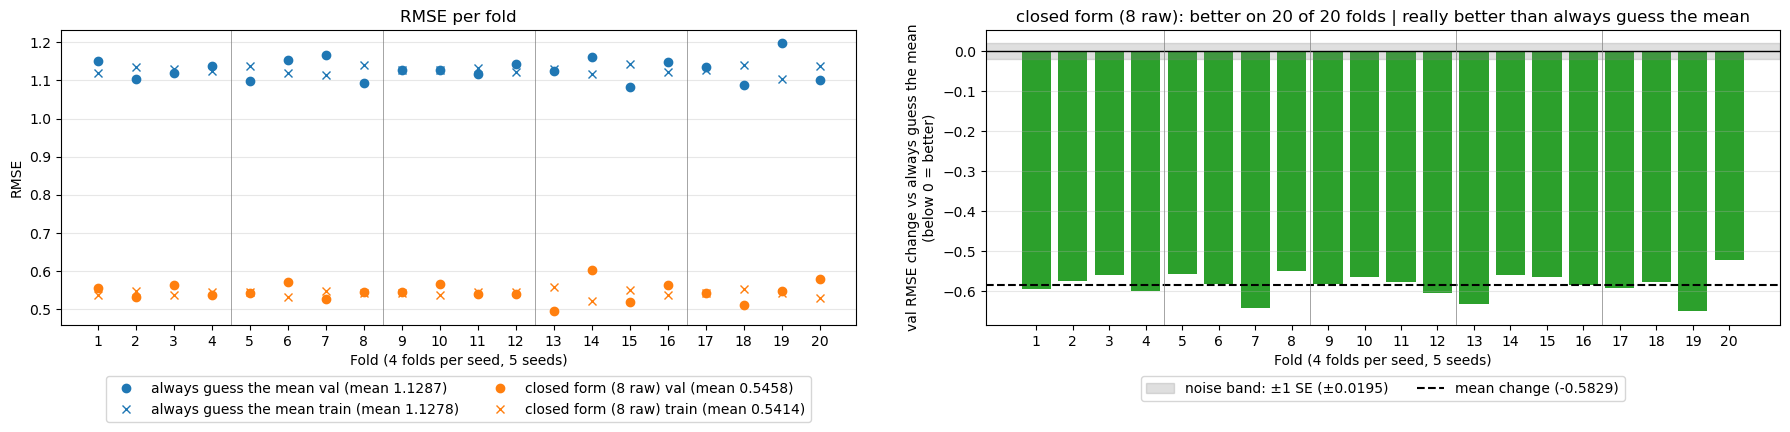

In [4]:
closedform_lr_val_scores, closedform_lr_train_scores = CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=LinearRegression(),
	folds=FOLDS
)

cv_fold_scores(
	baseline=(dummy_val_scores, dummy_train_scores),
	compare=(closedform_lr_val_scores, closedform_lr_train_scores),
	baseline_name="always guess the mean",
	compare_name="closed form (8 raw)",
)

**Closed form against the baseline.** Always guessing the mean scores a validation RMSE of 1.1287. Closed form linear regression on the 8 raw columns scores 0.5458, a change of -0.5829 (SE 0.0195), and is better on all 20 folds. Its training RMSE (0.5414) is close to its validation RMSE, so it is not overfitting. 0.5458 is the score that the Missing Rows and Feature Shapes experiments are measured against.

# Missing Rows
Every experiment above trains on complete rows only: rows with a missing value are dropped. The experiments in this section keep those rows in training and fill the missing values with an imputer, fit on the training fold only.

The validation rows are the same complete rows in every run, so the validation RMSE (dots) is comparable across runs. The training RMSE (x marks) is not: the imputed runs are scored on more training rows.

In [5]:
complete_rows = train_df[FEATURES].notna().all(axis=1)
print(f"complete rows: {complete_rows.sum()} | incomplete rows: {(~complete_rows).sum()}")

rows_scores = {}

complete rows: 1374 | incomplete rows: 185


## Missing Rows > Median Imputer

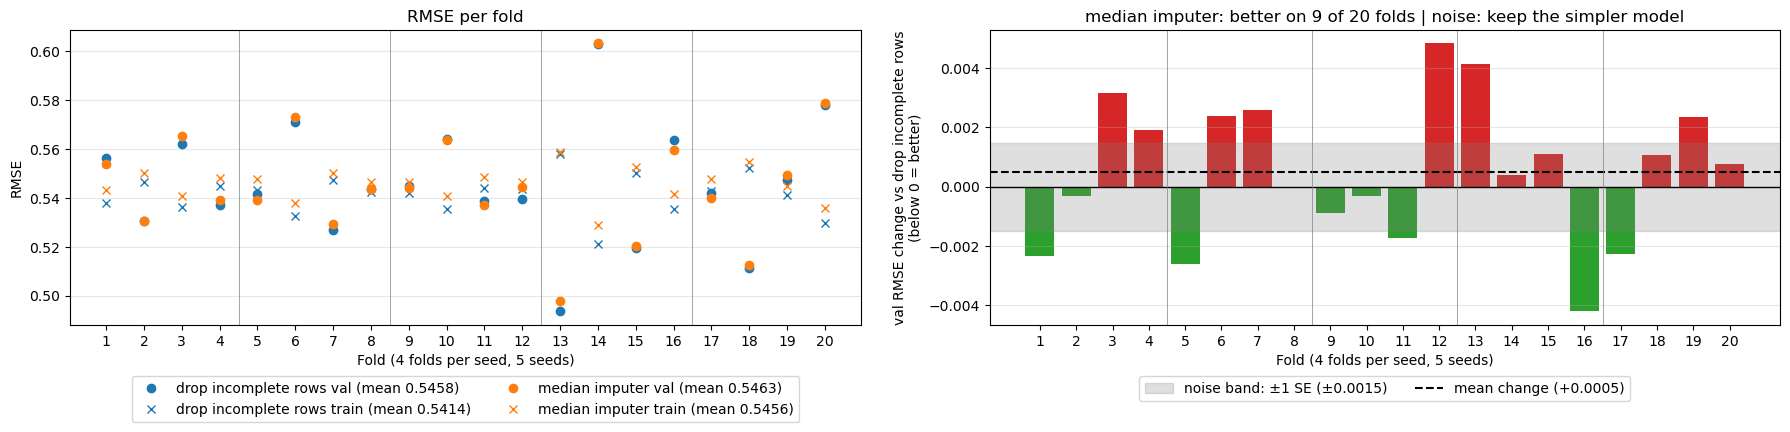

In [6]:
rows_scores["median"] = CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=FEATURES,
	estimator=make_pipeline(SimpleImputer(strategy="median"), LinearRegression()),
	folds=FOLDS,
	drop_incomplete=False
)

cv_fold_scores(
	baseline=(closedform_lr_val_scores, closedform_lr_train_scores),
	compare=rows_scores["median"],
	baseline_name="drop incomplete rows",
	compare_name="median imputer",
)

## Missing Rows > Other Imputers
- **median + indicator:** the median imputer, plus a 0/1 column per feature marking the rows that were filled.
- **KNN:** fills a missing value from the 5 most similar rows. The features are scaled first so no single feature dominates the distance.
- **iterative:** predicts each feature with missing values from the other features.

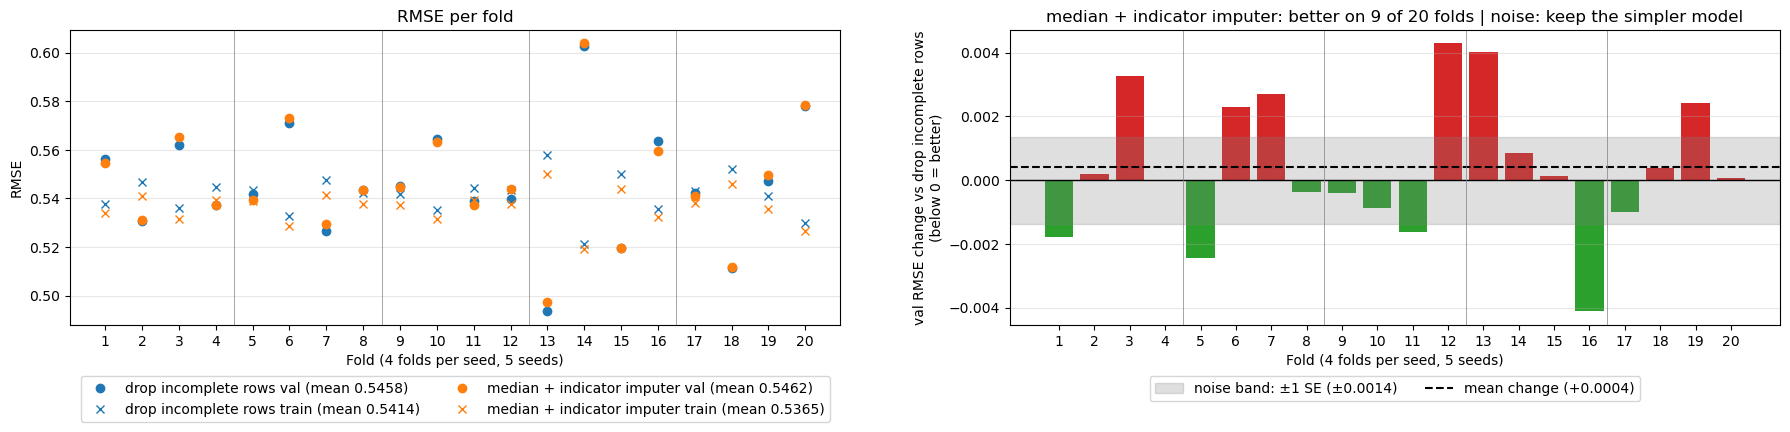

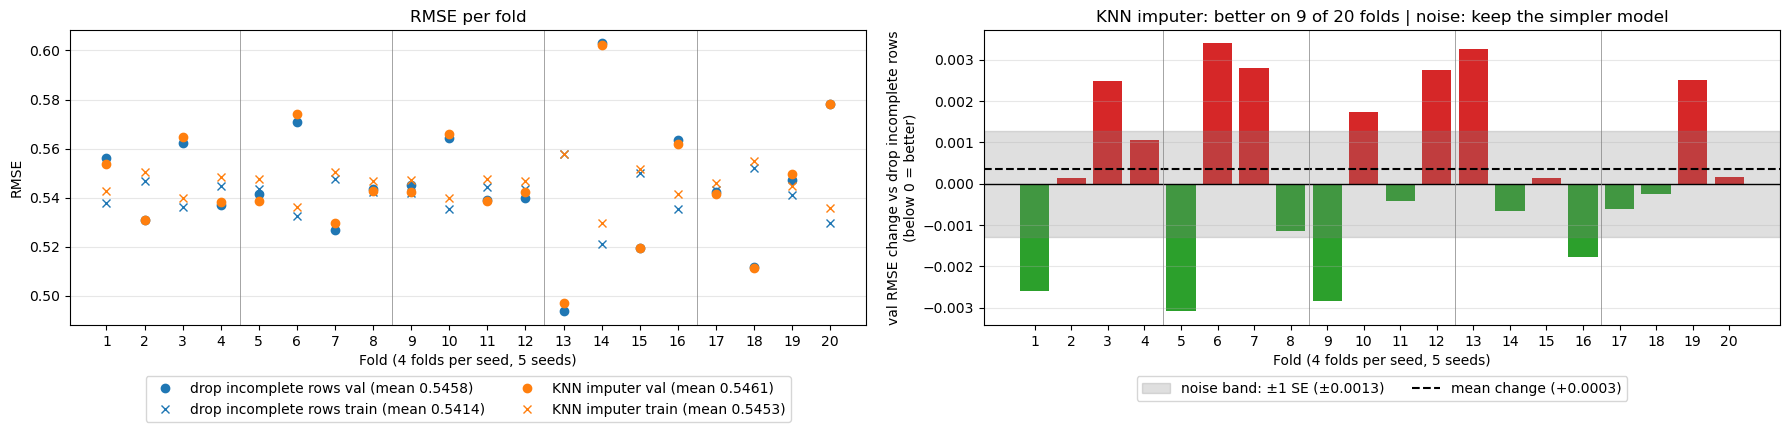

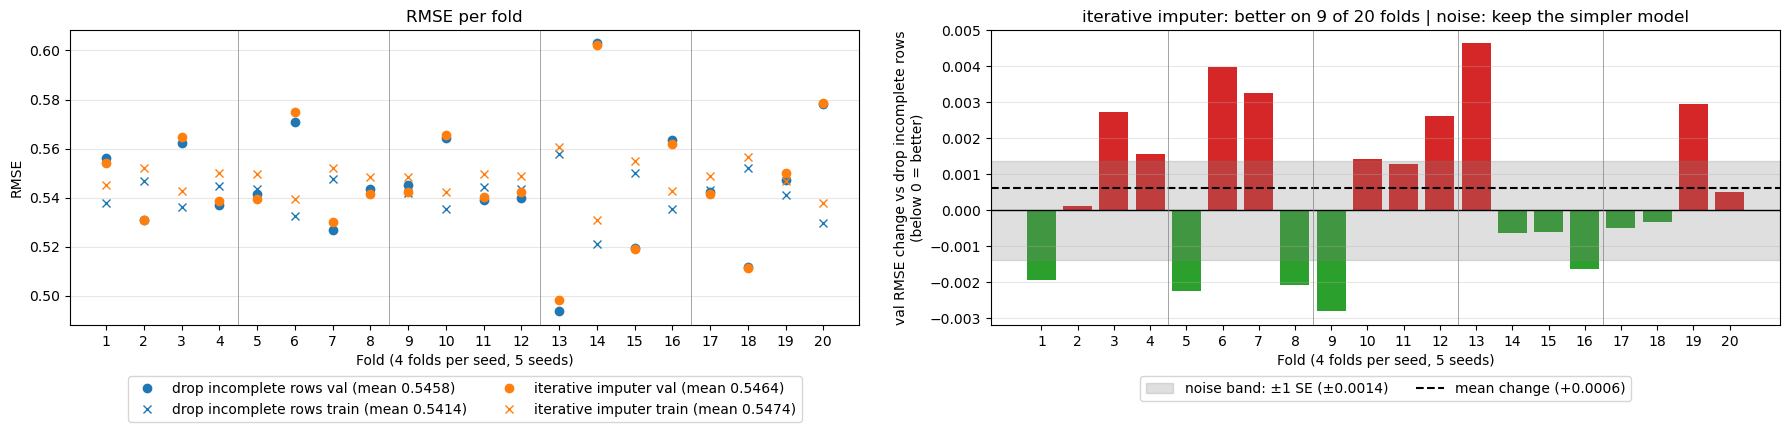

In [7]:
IMPUTERS = {
	"median + indicator": make_pipeline(SimpleImputer(strategy="median", add_indicator=True), LinearRegression()),
	"KNN": make_pipeline(StandardScaler(), KNNImputer(), LinearRegression()),
	"iterative": make_pipeline(IterativeImputer(random_state=42), LinearRegression()),
}

for name, estimator in IMPUTERS.items():
	rows_scores[name] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=FEATURES,
		estimator=estimator,
		folds=FOLDS,
		drop_incomplete=False
	)

	cv_fold_scores(
		baseline=(closedform_lr_val_scores, closedform_lr_train_scores),
		compare=rows_scores[name],
		baseline_name="drop incomplete rows",
		compare_name=f"{name} imputer",
	)

## Missing Rows Summary

In [8]:
rows_runs = {"drop incomplete rows": (closedform_lr_val_scores, closedform_lr_train_scores)}
for name, val_train in rows_scores.items():
	rows_runs[f"{name} imputer"] = val_train

rows_summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs drop": (val - closedform_lr_val_scores).mean(),
		"SE": standard_error(diff=val - closedform_lr_val_scores),
		"folds better": np.sum(val < closedform_lr_val_scores),
	}
	for name, (val, train) in rows_runs.items()
}).T.sort_values("change vs drop")
rows_summary["folds better"] = rows_summary["folds better"].astype(int)
rows_summary["change vs drop"] = rows_summary["change vs drop"].map(np.format_float_positional)
rows_summary

,val RMSE,train RMSE,change vs drop,SE,folds better
drop incomplete rows,0.545777,0.541366,0.,0.000000,0
KNN imputer,0.546123,0.545277,0.0003456339349461435,0.001283,9
median + indicator imputer,0.546174,0.536530,0.00039701060015300547,0.001362,9
median imputer,0.546278,0.545627,0.0005007072794495776,0.001482,9
iterative imputer,0.546395,0.547368,0.0006172819790026457,0.001382,9


**Impact of imputing the missing rows.** The training data has 185 incomplete rows next to 1374 complete ones. Keeping them in training with an imputer does not help. All four imputers score a validation RMSE between 0.5461 (KNN) and 0.5464 (iterative), against 0.5458 for dropping the rows. Every change is an increase (+0.0003 to +0.0006) and smaller than its SE (0.0013 to 0.0015), so all four are within noise, and each is better on only 9 of 20 folds. The simpler choice is kept: every experiment below drops the incomplete rows and uses no imputer.

# Feature Shapes
Q1C found that no attribute's relationship with Life Ladder is a straight line, and proposed one shape per attribute. Each experiment in this section changes one attribute to its Q1C shape and keeps the other seven raw. Every run uses closed form `LinearRegression` on complete rows, compared with the 8 raw columns.

- **hinge:** `max(0, x - t)`. It is 0 at or below the threshold t and grows above it, so the fitted line can bend at t.
- **indicator:** 1 when x is below t, else 0, so the prediction can jump at t.

The thresholds are fixed at Q1C's values. Q1C chose them using every training row, including the rows these folds validate on, so the gains below are slightly optimistic.

## Feature Shapes > Life Expectancy Hinge
The raw Healthy life expectancy column is replaced by its hinge at 57.5: flat below 57.5, one slope above.

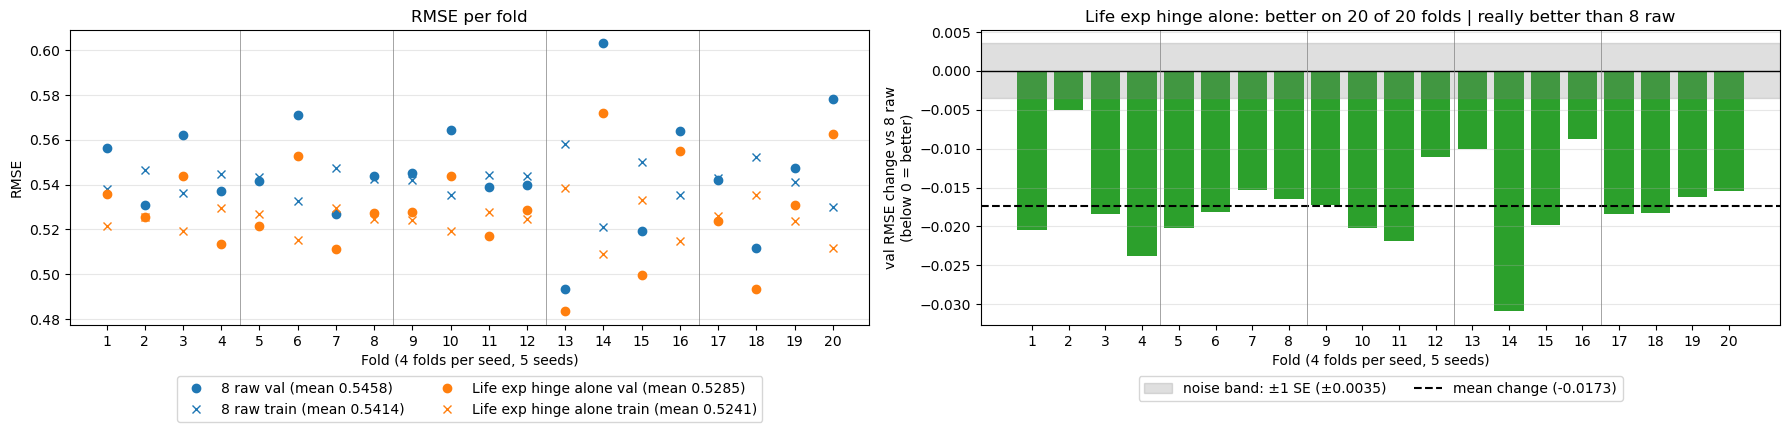

In [9]:
LIFE_EXP = COLUMNS['HLEAB']['col']
train_df["Life exp hinge 57.5"] = np.maximum(0, train_df[LIFE_EXP] - 57.5)

shape_scores = {}
shape_scores["Life exp hinge alone"] = CROSS_VALIDATION.cv_model(
	data=train_df,
	# the 8 raw columns, with raw life expectancy swapped for its hinge
	columns=[col for col in FEATURES if col != LIFE_EXP] + ["Life exp hinge 57.5"],
	estimator=LinearRegression(),
	folds=FOLDS
)

cv_fold_scores(
	baseline=(closedform_lr_val_scores, closedform_lr_train_scores),
	compare=shape_scores["Life exp hinge alone"],
	baseline_name="8 raw",
	compare_name="Life exp hinge alone",
)

## Feature Shapes > Other Shapes

| Experiment | New columns | Raw column |
|---|---|---|
| GDP two bends | hinge at 10.3, hinge at 10.9 | kept |
| Social hinge | hinge at 0.84 | kept |
| Freedom hinge | hinge at 0.8 | kept |
| Pos affect indicator | below 0.749 | kept |
| Corruption indicator | below 0.58 | kept |
| Neg affect hinge alone | hinge at 0.2 | replaced |
| Generosity indicator alone | below 0.087 | replaced |

In [10]:
GDP = COLUMNS['LGDP']['col']
SOCIAL = COLUMNS['SS']['col']
FREEDOM = COLUMNS['FTMLC']['col']
GENEROSITY = COLUMNS['G']['col']
CORRUPTION = COLUMNS['POC']['col']
POS_AFFECT = COLUMNS['PA']['col']
NEG_AFFECT = COLUMNS['NA']['col']

# hinge: max(0, x - t)
train_df["GDP hinge 10.3"] = np.maximum(0, train_df[GDP] - 10.3)
train_df["GDP hinge 10.9"] = np.maximum(0, train_df[GDP] - 10.9)
train_df["Social hinge 0.84"] = np.maximum(0, train_df[SOCIAL] - 0.84)
train_df["Freedom hinge 0.8"] = np.maximum(0, train_df[FREEDOM] - 0.8)
train_df["Neg affect hinge 0.2"] = np.maximum(0, train_df[NEG_AFFECT] - 0.2)

# indicator: 1 when x < t, else 0. A missing x gives 0, which is harmless: that row is dropped anyway
# because its raw value is still missing.
train_df["Pos affect below 0.749"] = (train_df[POS_AFFECT] < 0.749).astype(float)
train_df["Corruption below 0.58"] = (train_df[CORRUPTION] < 0.58).astype(float)
train_df["Generosity below 0.087"] = (train_df[GENEROSITY] < 0.087).astype(float)

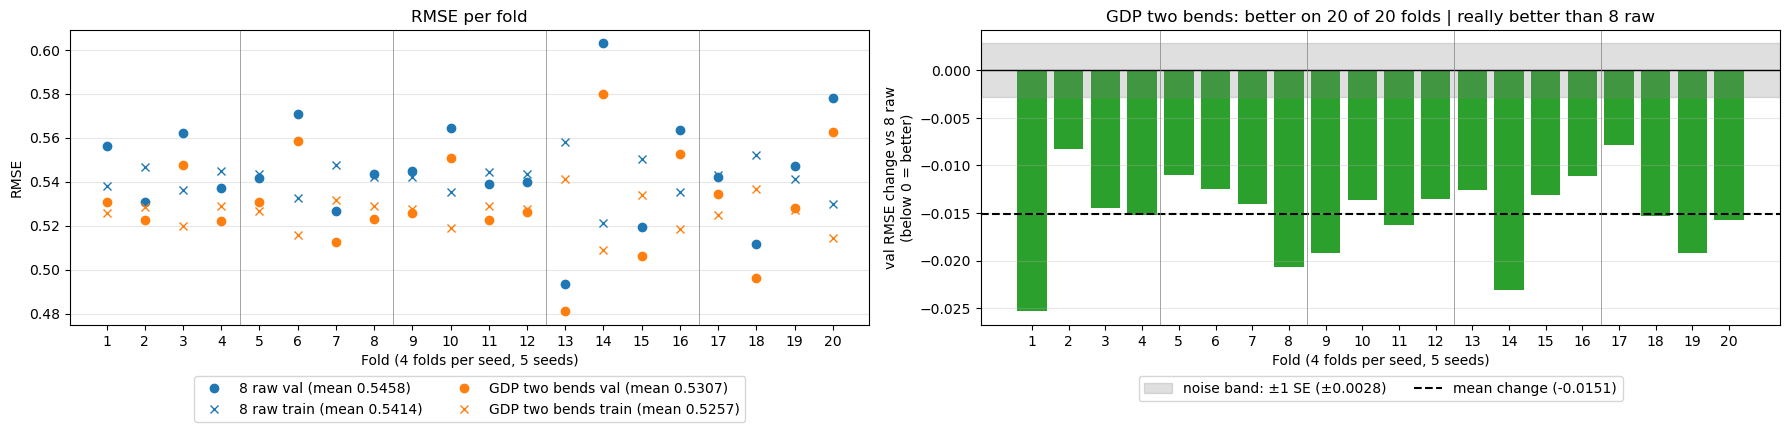

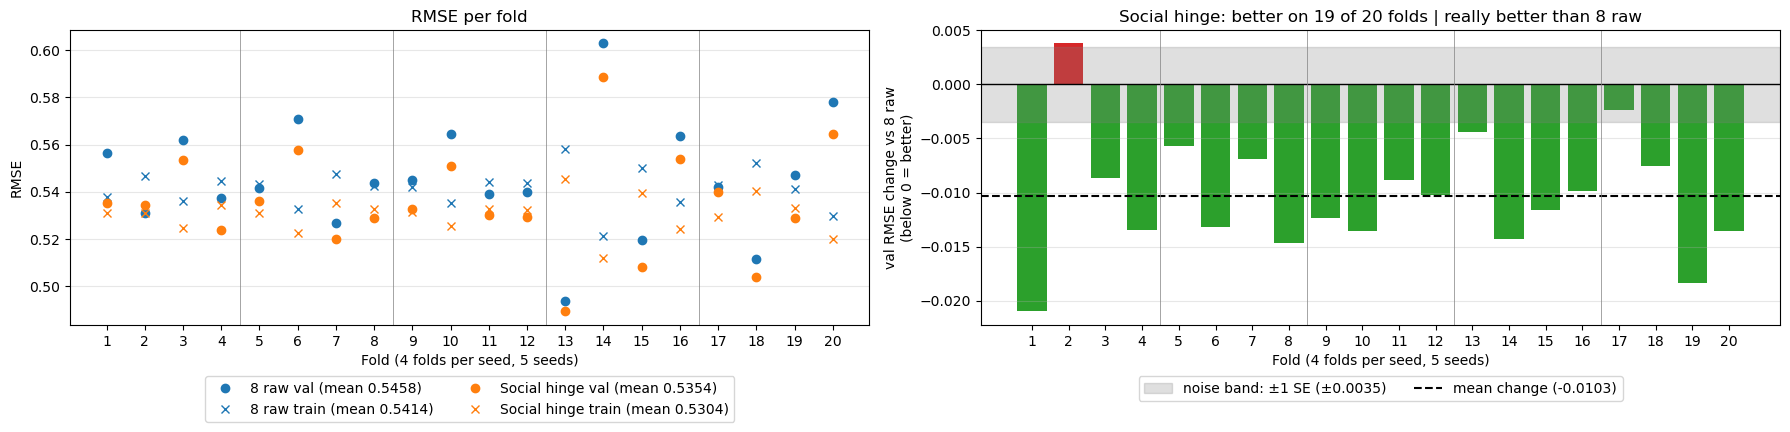

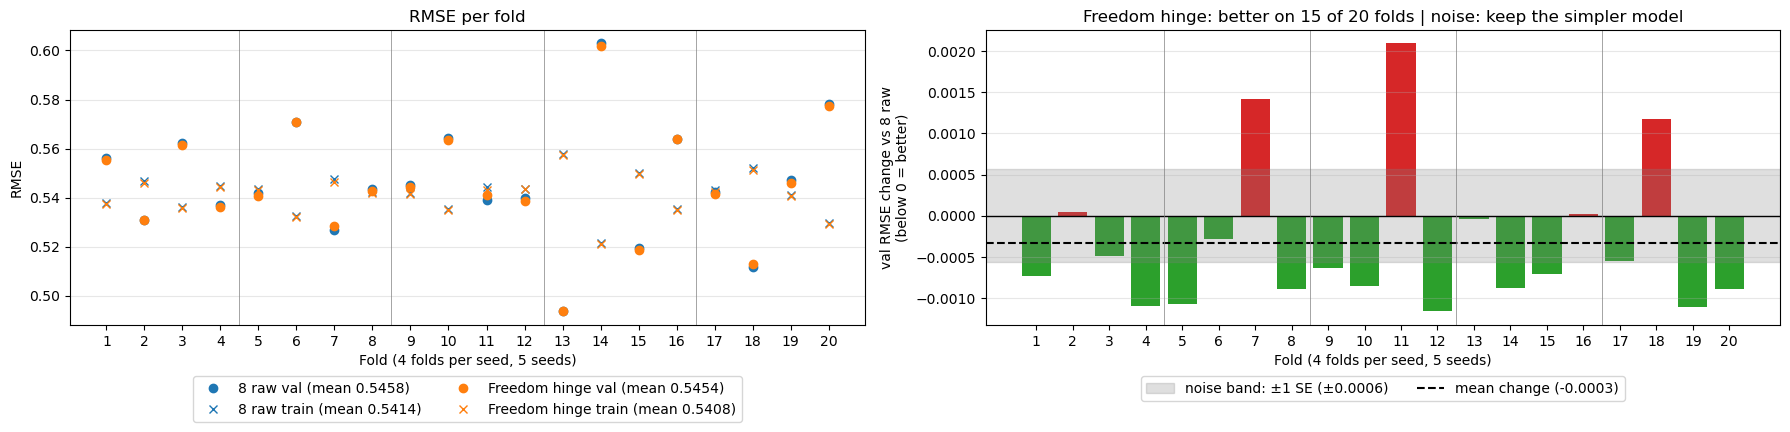

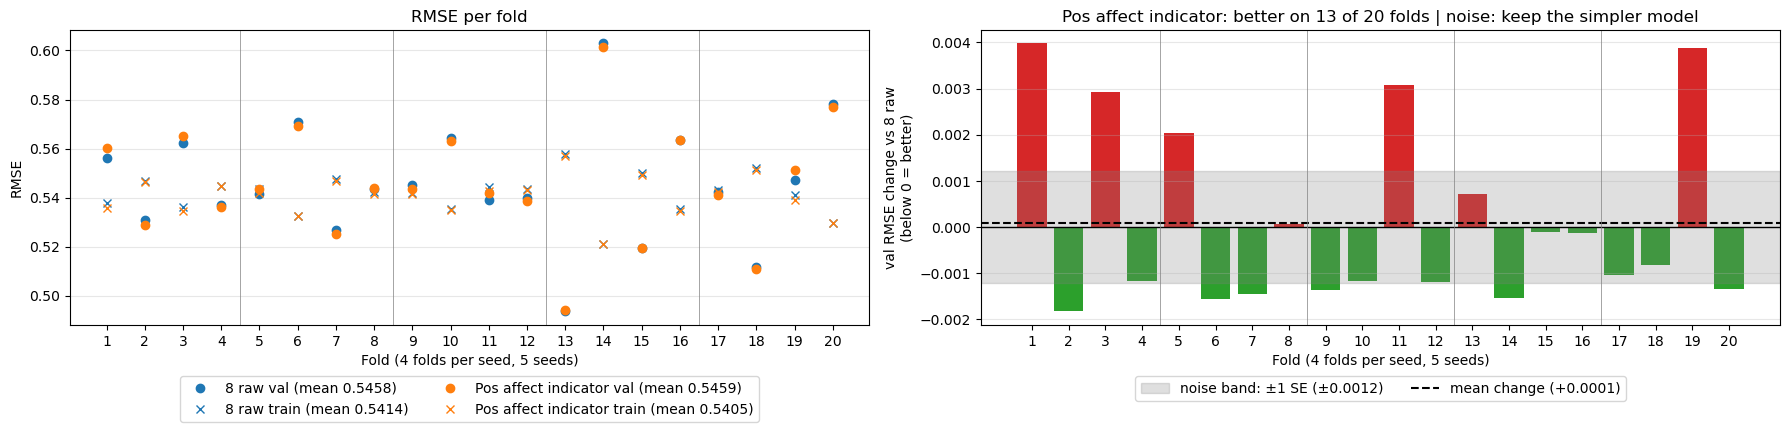

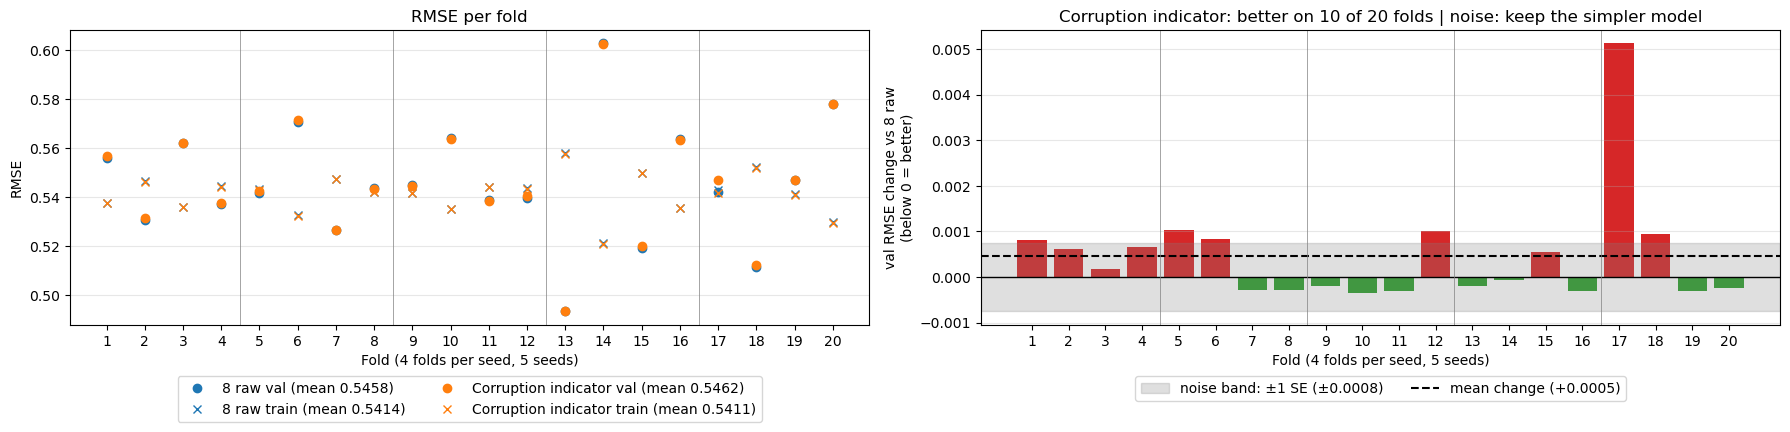

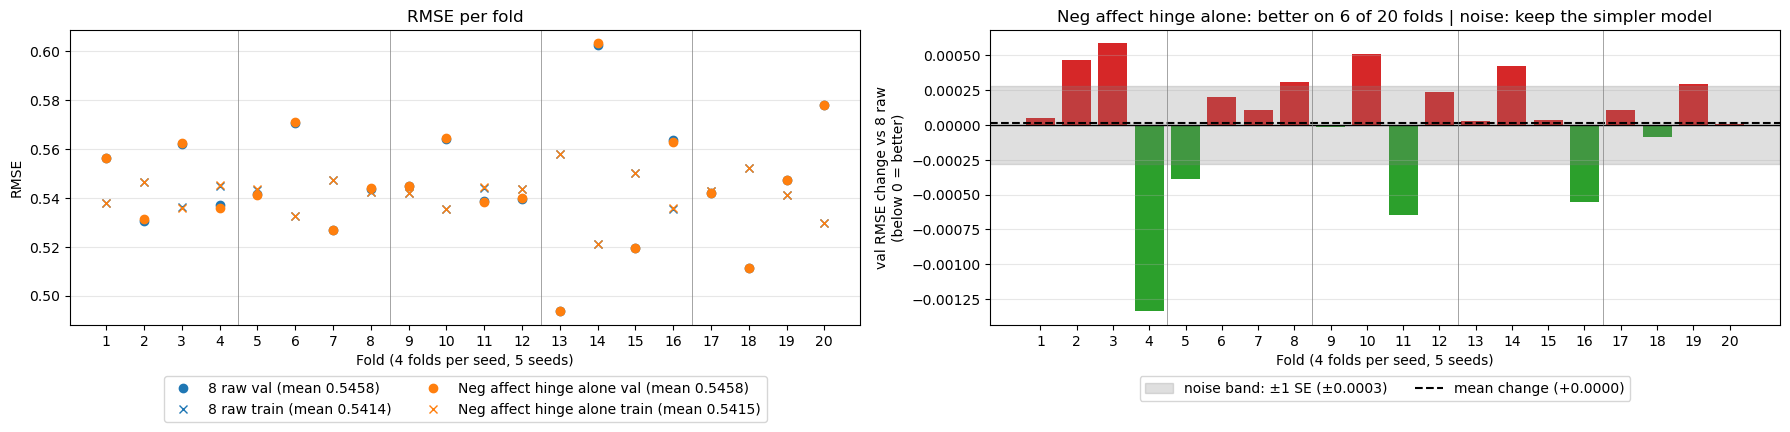

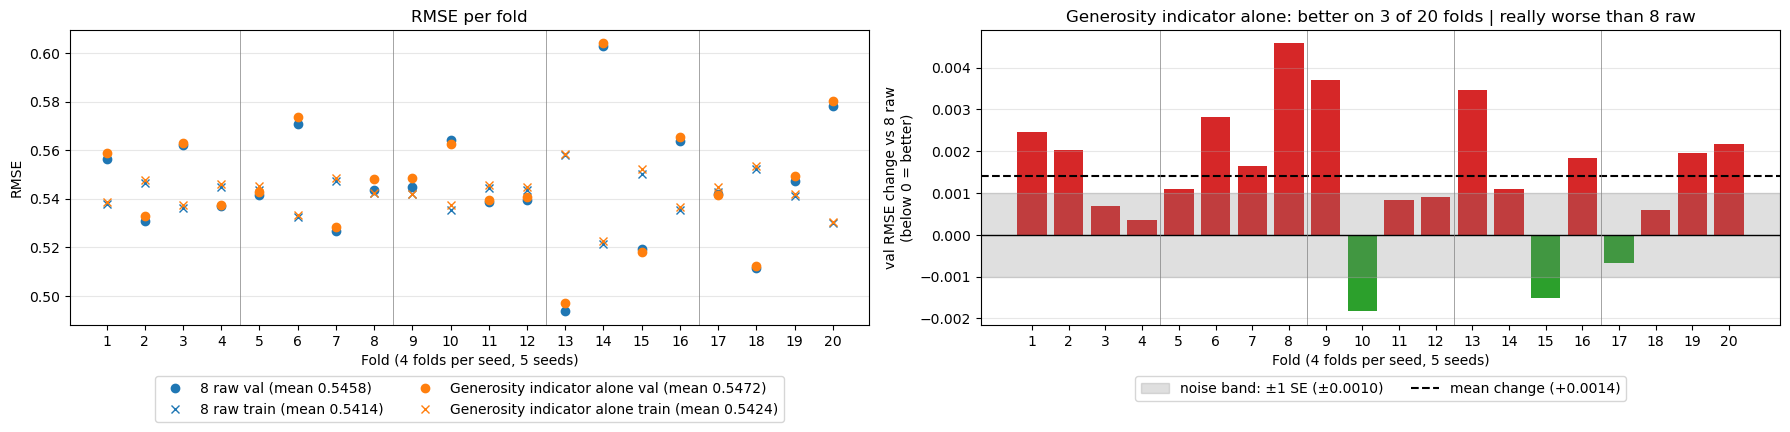

In [11]:
# the columns each experiment is fit on: the 8 raw columns with one attribute changed
SHAPES = {
	"GDP two bends": FEATURES + ["GDP hinge 10.3", "GDP hinge 10.9"],
	"Social hinge": FEATURES + ["Social hinge 0.84"],
	"Freedom hinge": FEATURES + ["Freedom hinge 0.8"],
	"Pos affect indicator": FEATURES + ["Pos affect below 0.749"],
	"Corruption indicator": FEATURES + ["Corruption below 0.58"],
	"Neg affect hinge alone": [col for col in FEATURES if col != NEG_AFFECT] + ["Neg affect hinge 0.2"],
	"Generosity indicator alone": [col for col in FEATURES if col != GENEROSITY] + ["Generosity below 0.087"],
}

for name, columns in SHAPES.items():
	shape_scores[name] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=columns,
		estimator=LinearRegression(),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(closedform_lr_val_scores, closedform_lr_train_scores),
		compare=shape_scores[name],
		baseline_name="8 raw",
		compare_name=name,
	)

## Feature Shapes Summary

In [12]:
shape_runs = {"8 raw": (closedform_lr_val_scores, closedform_lr_train_scores)}
for name, val_train in shape_scores.items():
	shape_runs[name] = val_train

shape_summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs raw": (val - closedform_lr_val_scores).mean(),
		"SE": standard_error(diff=val - closedform_lr_val_scores),
		"folds better": np.sum(val < closedform_lr_val_scores),
	}
	for name, (val, train) in shape_runs.items()
}).T.sort_values("change vs raw")
shape_summary["folds better"] = shape_summary["folds better"].astype(int)
shape_summary["change vs raw"] = shape_summary["change vs raw"].map(np.format_float_positional)
shape_summary

,val RMSE,train RMSE,change vs raw,SE,folds better
Life exp hinge alone,0.528464,0.524059,-0.017312920014803744,0.003502,20
GDP two bends,0.530668,0.525678,-0.015109736897159512,0.002804,20
Social hinge,0.535436,0.530359,-0.010341531878684366,0.003483,19
Freedom hinge,0.545447,0.540790,-0.00033028525469692706,0.000561,15
8 raw,0.545777,0.541366,0.,0.000000,0
Neg affect hinge alone,0.545795,0.541474,0.000017794666835380113,0.000283,6
Pos affect indicator,0.545874,0.540496,0.0000964054774471479,0.001215,13
Corruption indicator,0.546239,0.541131,0.000461769449467192,0.000752,10
Generosity indicator alone,0.547184,0.542450,0.0014067914835771077,0.001009,3


**Impact of each shape on its own.** Three of the eight shapes beat the 8 raw columns (0.5458) by more than 1 SE. The life expectancy hinge lowers validation RMSE to 0.5285 (-0.0173, SE 0.0035), GDP's two bends to 0.5307 (-0.0151, SE 0.0028) and the Social support hinge to 0.5354 (-0.0103, SE 0.0035). The first two are better on all 20 folds and the third on 19. Their training RMSE falls with it (0.5241, 0.5257 and 0.5304, against 0.5414 for 8 raw), so the gain is a better fit, not overfitting. Four shapes are within noise, each with a change smaller than its SE: the Freedom hinge (0.5454, -0.0003, SE 0.0006), the Neg affect hinge alone (0.5458), the Pos affect indicator (0.5459) and the Corruption indicator (0.5462). The Generosity indicator alone is the only shape that is really worse (0.5472, +0.0014, SE 0.0010, better on 3 of 20 folds). The three winners go into the combined model below. The other five attributes stay raw.

## Feature Shapes > Combined
The shapes that beat the 8 raw columns by more than 1 SE on their own, put in one model. The list is typed by hand from the summary table above.

11


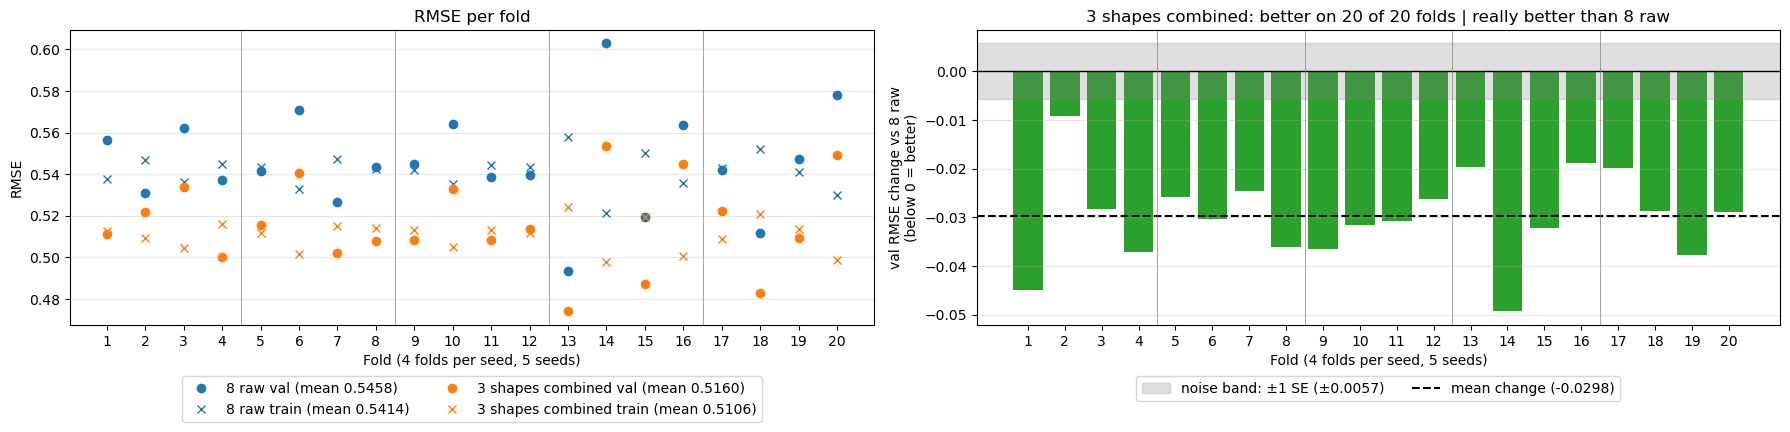

In [13]:
# raw Healthy life expectancy (LIFE_EXP) is left out on purpose: its hinge replaces it.
# "Raw Life Expectancy Added Back" below checks that adding it back does not help.
BEST_FEATURES = [
	GDP, SOCIAL, FREEDOM, GENEROSITY, CORRUPTION, POS_AFFECT, NEG_AFFECT,
	"GDP hinge 10.3", "GDP hinge 10.9",
	"Life exp hinge 57.5",
	"Social hinge 0.84",
]
print(len(BEST_FEATURES))

best_closedform_val_scores, best_closedform_train_scores = CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=BEST_FEATURES,
	estimator=LinearRegression(),
	folds=FOLDS
)

cv_fold_scores(
	baseline=(closedform_lr_val_scores, closedform_lr_train_scores),
	compare=(best_closedform_val_scores, best_closedform_train_scores),
	baseline_name="8 raw",
	compare_name="3 shapes combined",
)

## Feature Shapes > Remove One
Each run takes one shape back out of the combined model, so that attribute goes back to its raw column. A shape that still earns its place next to the other two makes the model really worse when it is removed.

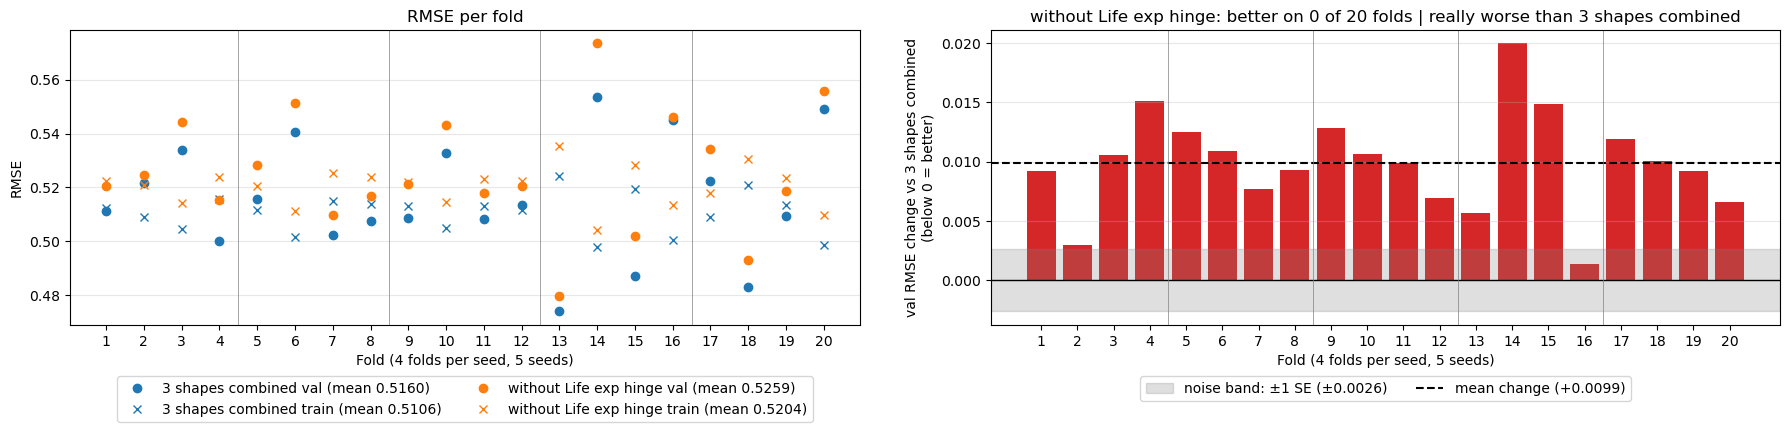

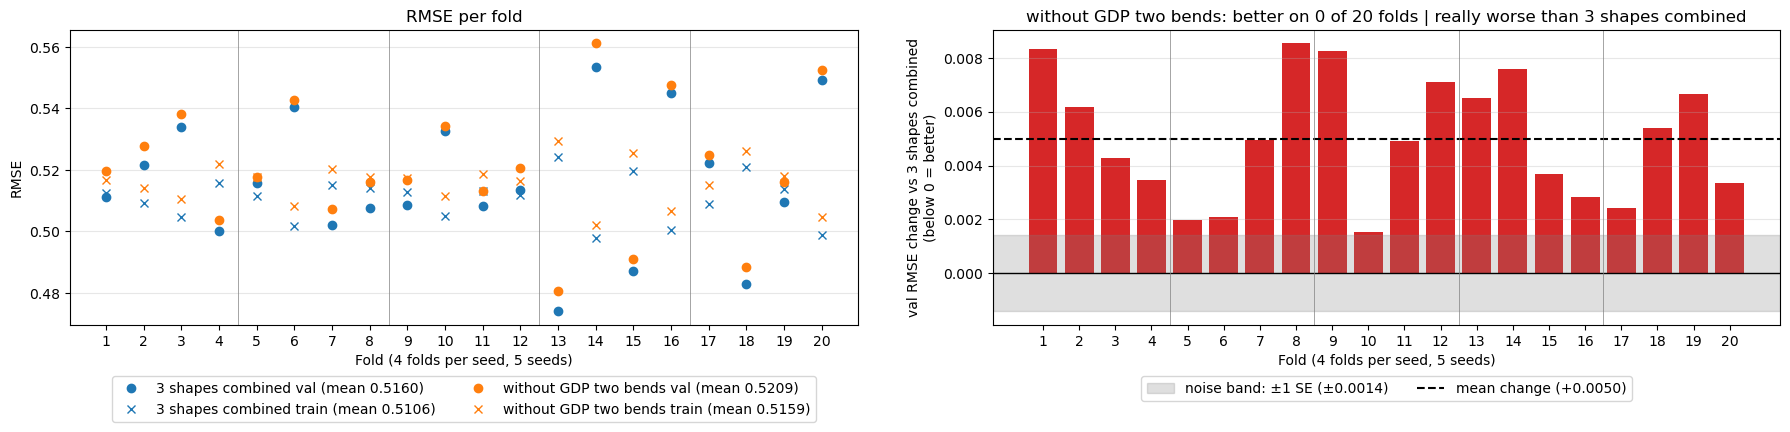

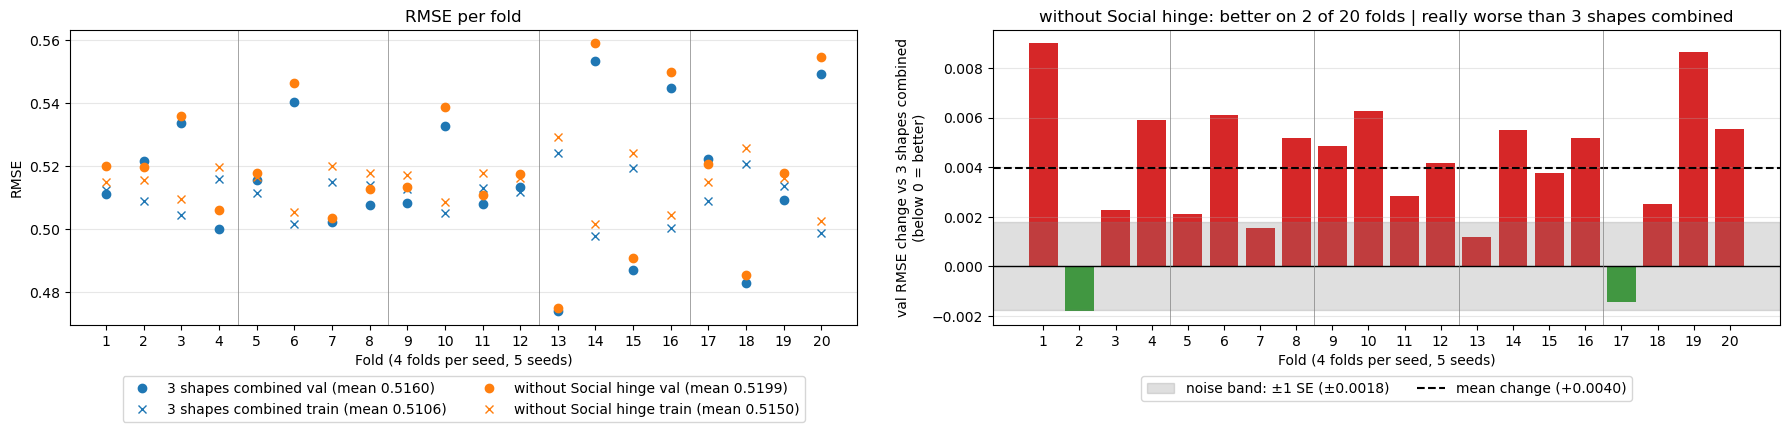

In [14]:
REMOVE_ONE = {
	"without Life exp hinge": [col for col in BEST_FEATURES if col != "Life exp hinge 57.5"] + [LIFE_EXP],
	"without GDP two bends": [col for col in BEST_FEATURES if col not in ("GDP hinge 10.3", "GDP hinge 10.9")],
	"without Social hinge": [col for col in BEST_FEATURES if col != "Social hinge 0.84"],
}

remove_one_scores = {}
for name, columns in REMOVE_ONE.items():
	remove_one_scores[name] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=columns,
		estimator=LinearRegression(),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(best_closedform_val_scores, best_closedform_train_scores),
		compare=remove_one_scores[name],
		baseline_name="3 shapes combined",
		compare_name=name,
	)

## Feature Shapes > Raw Life Expectancy Added Back
The combined model has no raw Healthy life expectancy column, because the hinge replaced it. This run adds the raw column back next to the hinge. If the slope below 57.5 matters, this is really better.

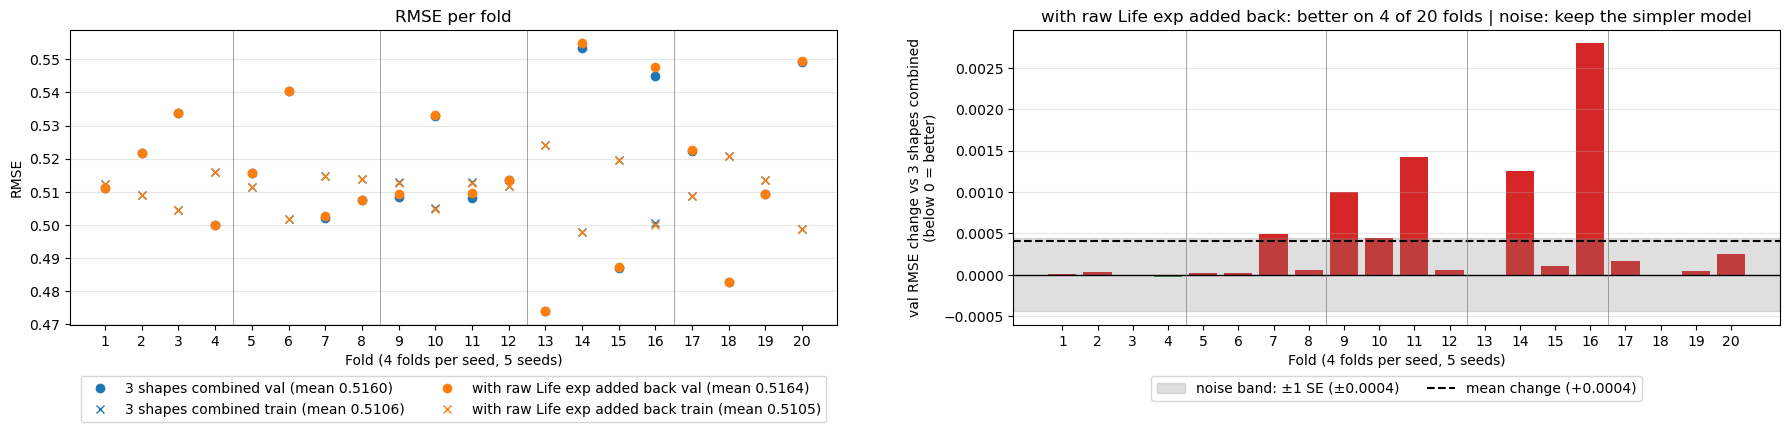

In [15]:
raw_life_exp_val_scores, raw_life_exp_train_scores = CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=BEST_FEATURES + [LIFE_EXP],
	estimator=LinearRegression(),
	folds=FOLDS
)

cv_fold_scores(
	baseline=(best_closedform_val_scores, best_closedform_train_scores),
	compare=(raw_life_exp_val_scores, raw_life_exp_train_scores),
	baseline_name="3 shapes combined",
	compare_name="with raw Life exp added back",
)

## Feature Shapes Combined Summary

In [16]:
combined_runs = {
	"3 shapes combined": (best_closedform_val_scores, best_closedform_train_scores),
	"8 raw": (closedform_lr_val_scores, closedform_lr_train_scores),
	"with raw Life exp added back": (raw_life_exp_val_scores, raw_life_exp_train_scores),
}
for name, val_train in remove_one_scores.items():
	combined_runs[name] = val_train

combined_summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs combined": (val - best_closedform_val_scores).mean(),
		"SE": standard_error(diff=val - best_closedform_val_scores),
		"folds better": np.sum(val < best_closedform_val_scores),
	}
	for name, (val, train) in combined_runs.items()
}).T.sort_values("change vs combined")
combined_summary["folds better"] = combined_summary["folds better"].astype(int)
combined_summary["change vs combined"] = combined_summary["change vs combined"].map(np.format_float_positional)
combined_summary

,val RMSE,train RMSE,change vs combined,SE,folds better
3 shapes combined,0.515953,0.510563,0.,0.000000,0
with raw Life exp added back,0.516359,0.510492,0.0004062226821214876,0.000442,4
without Social hinge,0.519922,0.515003,0.003969548934685846,0.001771,2
without GDP two bends,0.520949,0.515911,0.004995931310805088,0.001422,0
without Life exp hinge,0.525864,0.520420,0.009911441485767458,0.002613,0
8 raw,0.545777,0.541366,0.02982473204294895,0.005744,0


**Which shapes carry the gain.** Together the three shapes lower validation RMSE from 0.5458 to 0.5160, a change of 0.0298 (SE 0.0057), and the 8 raw columns are better on 0 of 20 folds. Each shape still earns its place next to the other two: taking it back out is worse by more than 1 SE. Removing the life expectancy hinge costs the most (0.5259, +0.0099, SE 0.0026), then GDP's two bends (0.5209, +0.0050, SE 0.0014), then the Social support hinge (0.5199, +0.0040, SE 0.0018). Each shape is worth less here than on its own (ex 0.0099 against 0.0173 for life expectancy), so the three overlap, but none is redundant. The combined model has no raw Healthy life expectancy column, because the hinge replaced it. Adding the raw column back does not help: 0.5164 (+0.00041, SE 0.00044) is within noise and better on only 4 of 20 folds, so the raw column stays out. Training RMSE (0.5106) stays close to validation RMSE (0.5160), so the extra columns do not overfit. These 11 columns (`BEST_FEATURES`) are the feature set carried forward.

# Stochastic Gradient Descent (SGD)
Every model from here on is fit on `BEST_FEATURES`, the 11 columns chosen in Feature Shapes, with rows that have a missing value dropped. Plain SGD is first compared with closed form on the same 11 columns. Every penalty and learning rate experiment is then compared with plain SGD.

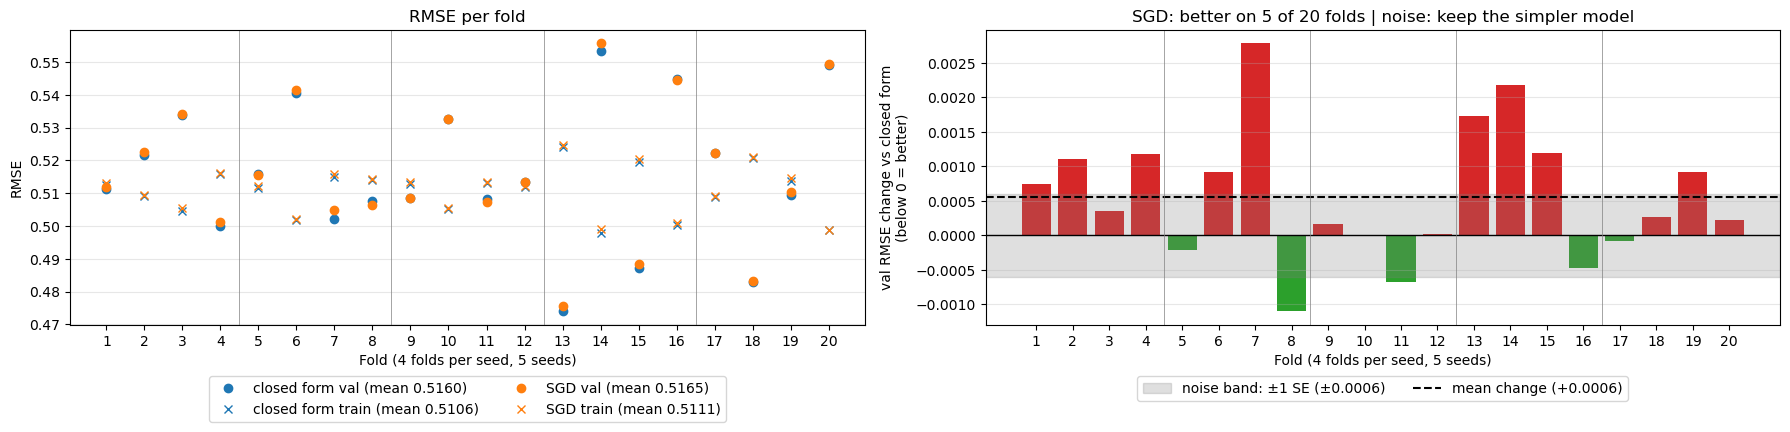

In [17]:
sgd_val_scores, sgd_train_scores = CROSS_VALIDATION.cv_model(
	data=train_df,
	columns=BEST_FEATURES,
	estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty=None, random_state=42)),
	folds=FOLDS
)

cv_fold_scores(
	baseline=(best_closedform_val_scores, best_closedform_train_scores),
	compare=(sgd_val_scores, sgd_train_scores),
	baseline_name="closed form",
	compare_name="SGD",
)

**SGD against closed form.** On the same 11 columns, plain SGD (no penalty) scores a validation RMSE of 0.5165 against 0.5160 for closed form. The chart's verdict is noise: the mean change (+0.0006) does not clear the ±1 SE band (±0.0006), and SGD is better on only 5 of 20 folds. Its training RMSE (0.5111) is also close to closed form's (0.5106). So SGD reaches the same fit as the closed form solution by iterating. Plain SGD is the baseline for every penalty and learning rate experiment below.

## Lasso

In [18]:
lasso_scores = {}

### Lasso > Penalty

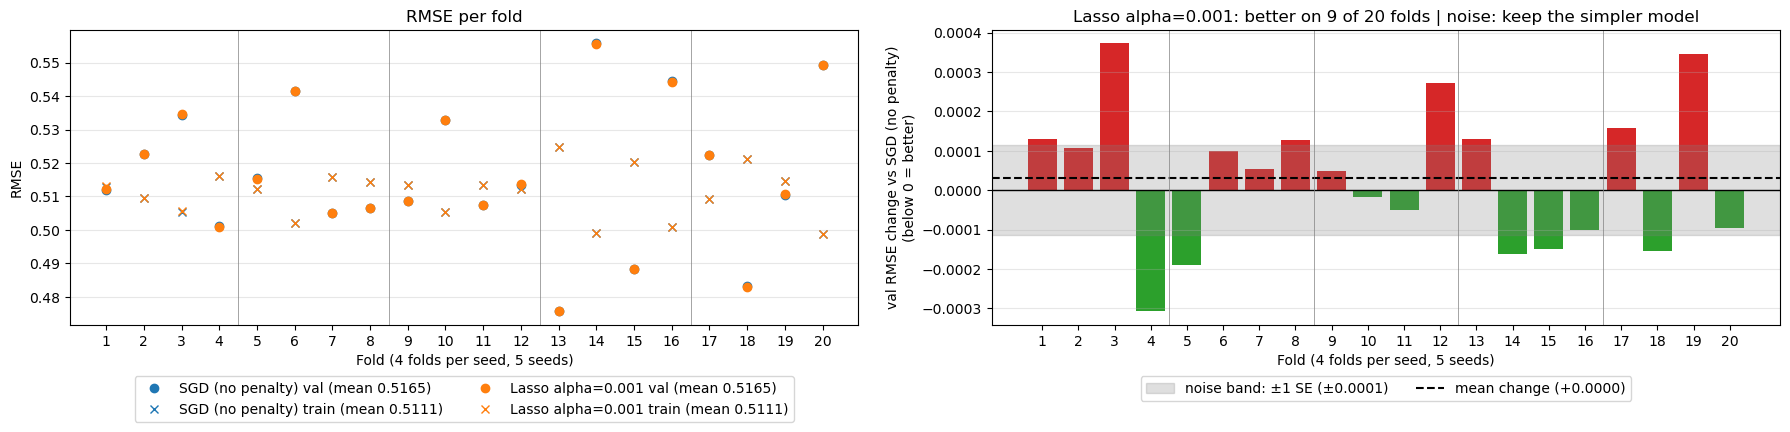

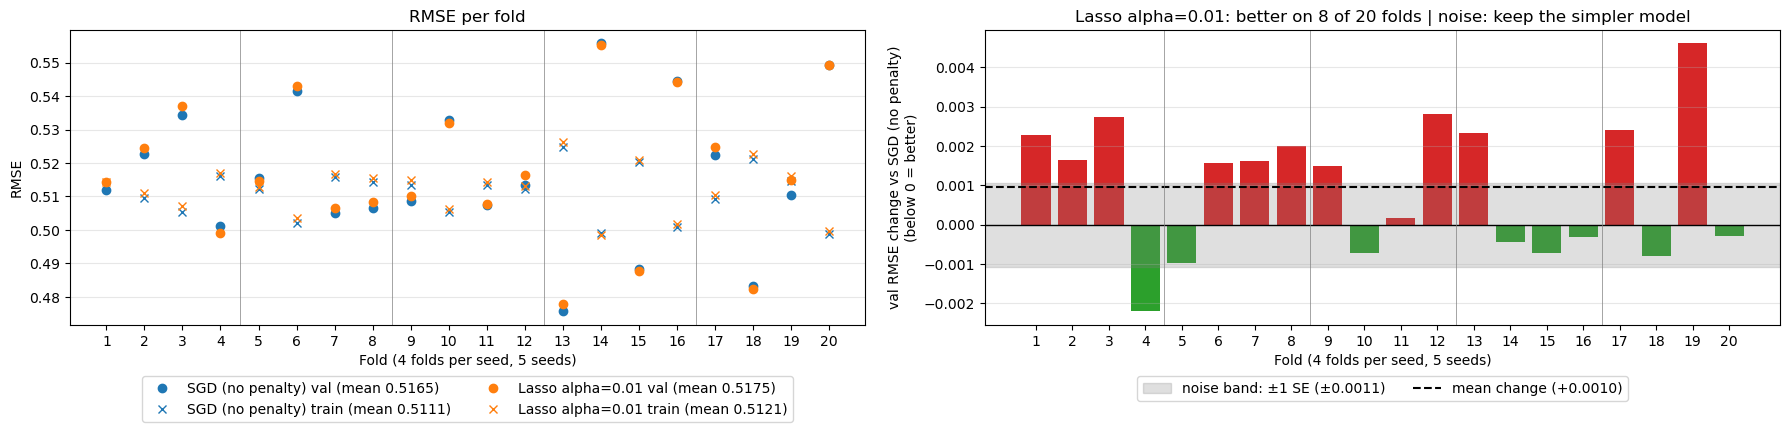

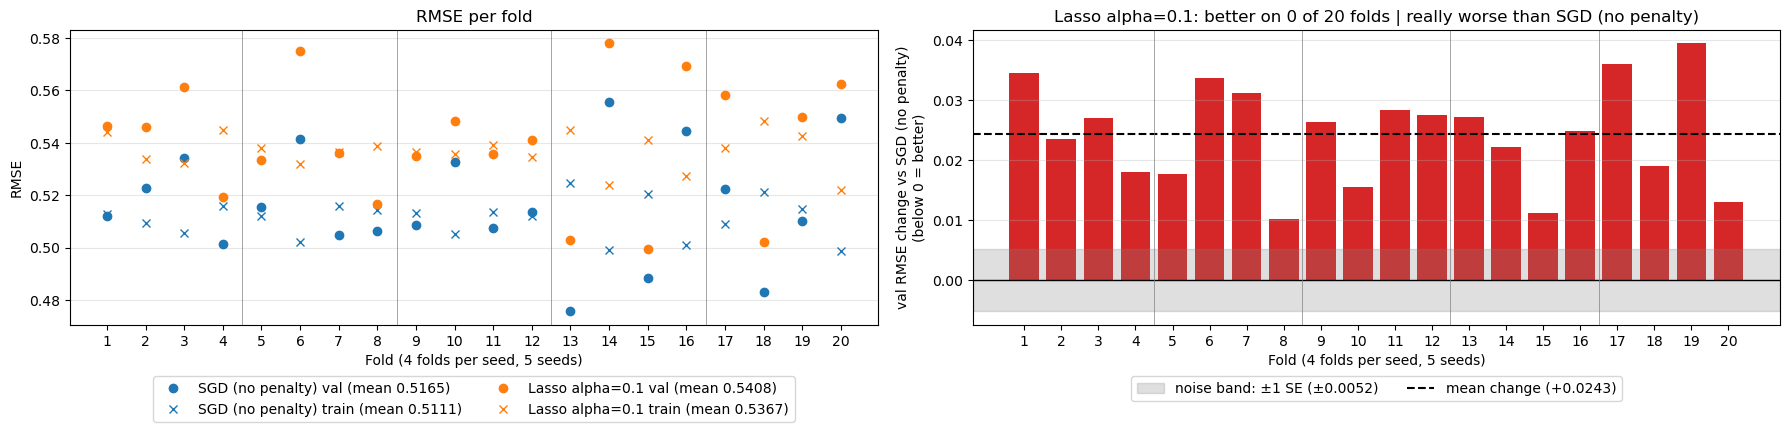

In [19]:
for alpha in ALPHAS:
	lasso_scores[("alpha", alpha)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l1', alpha=alpha, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=lasso_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Lasso alpha={alpha}",
	)

### Lasso > Learning Rate

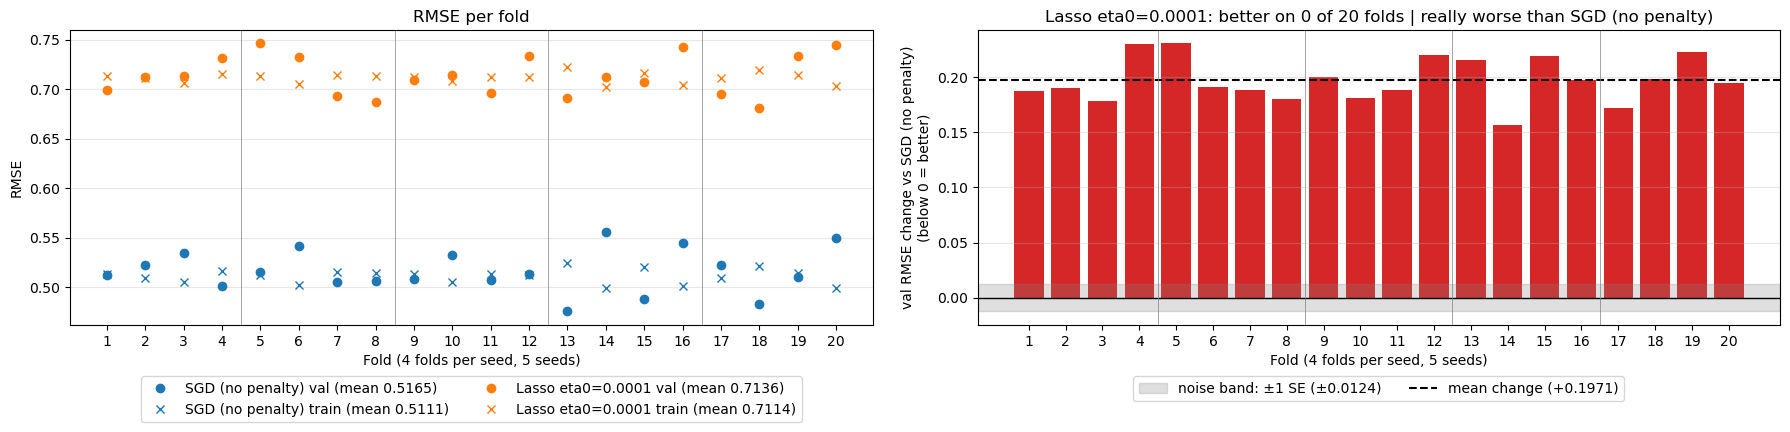

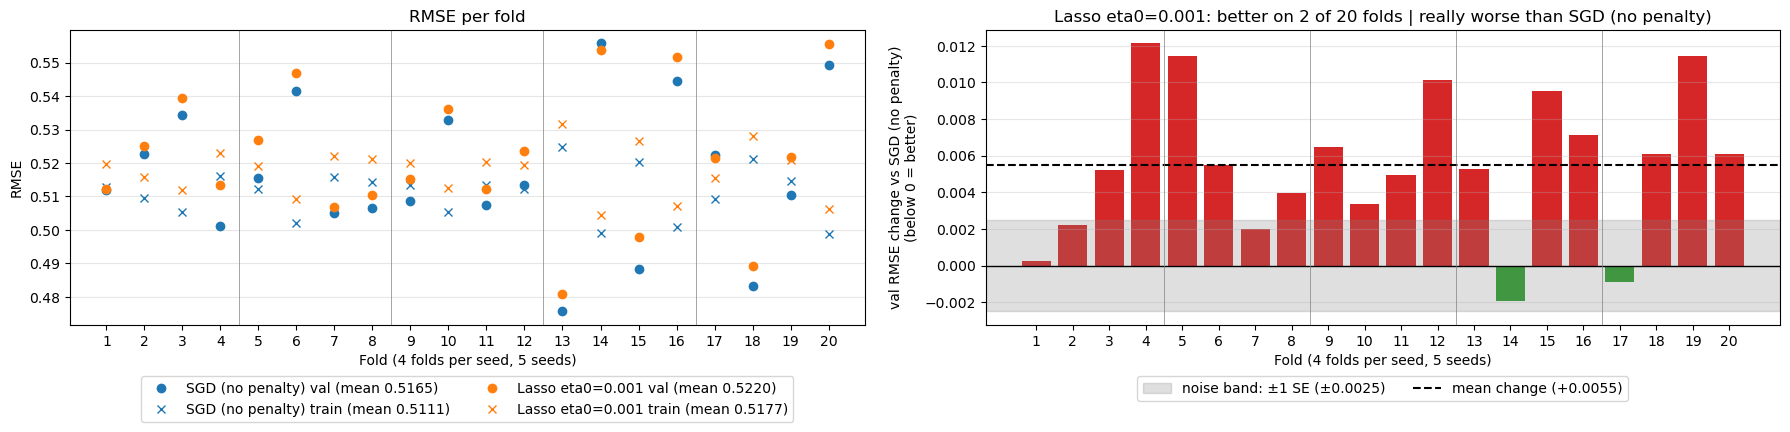

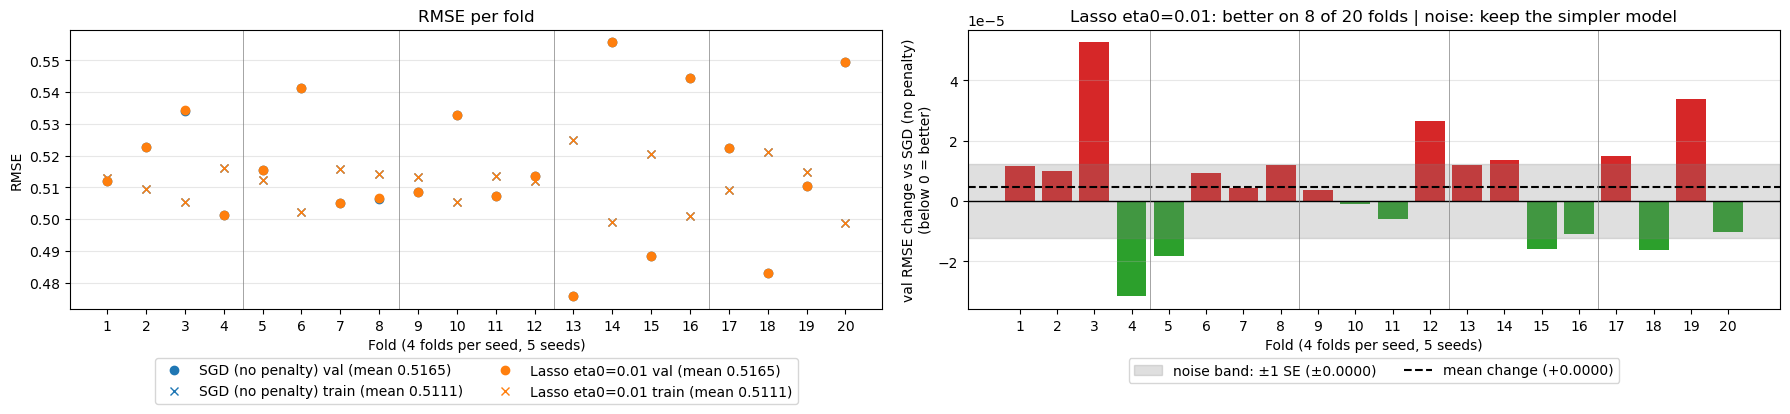

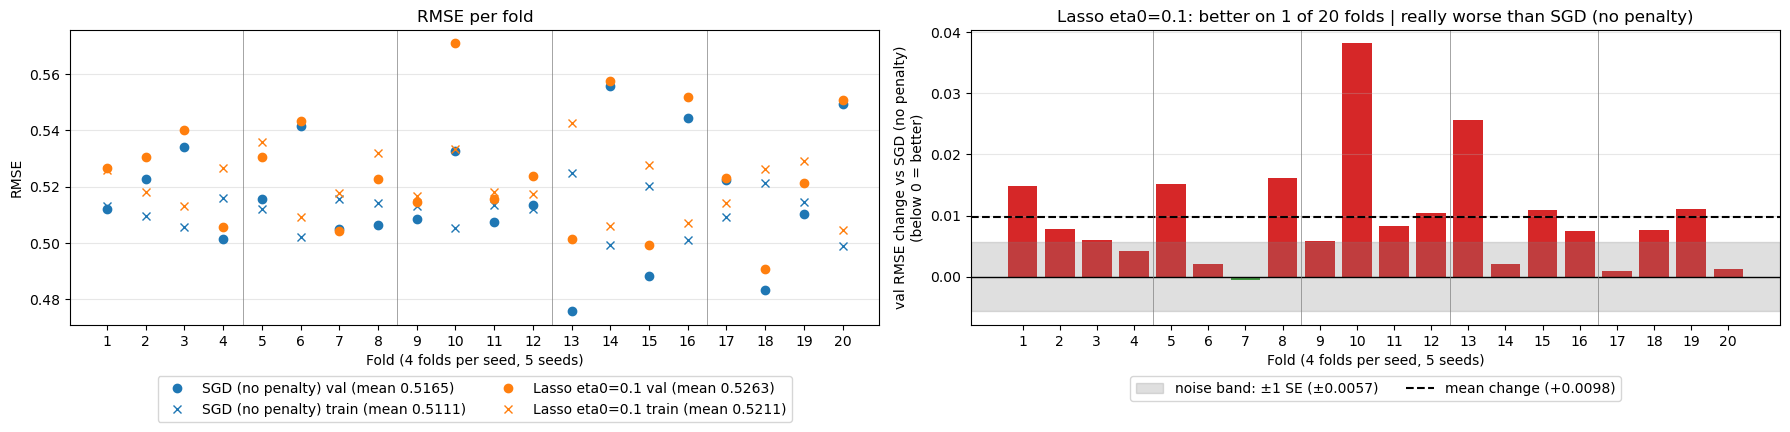

In [20]:
for eta0 in LEARNING_RATES:
	lasso_scores[("eta0", eta0)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l1', eta0=eta0, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=lasso_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Lasso eta0={eta0}",
	)

## Ridge

In [21]:
ridge_scores = {}

### Ridge > Penalty

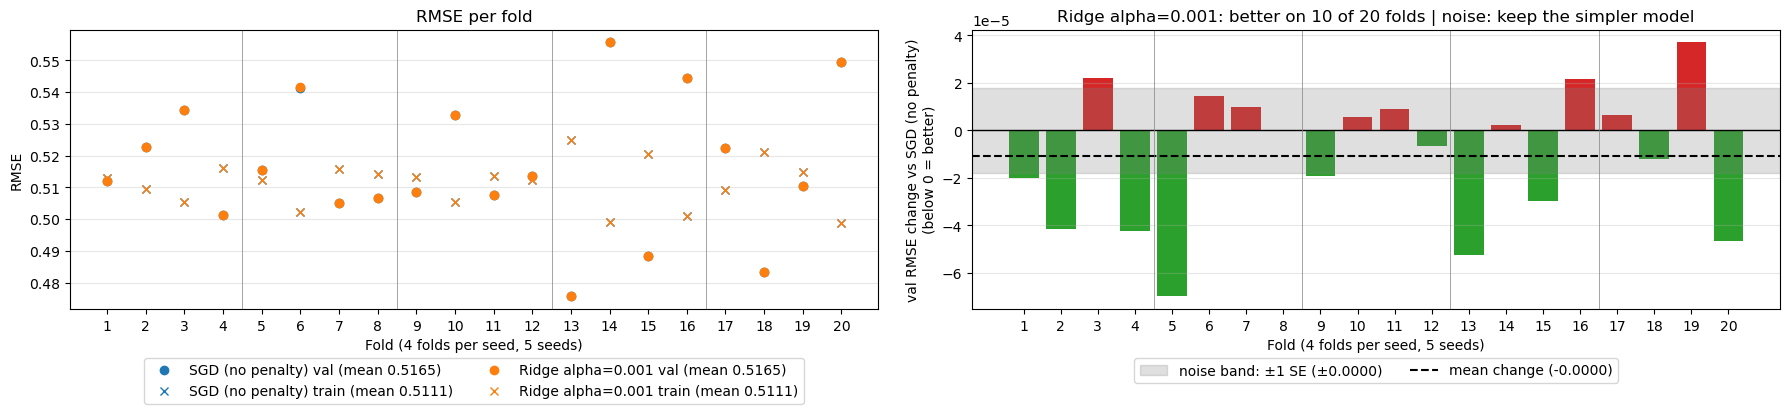

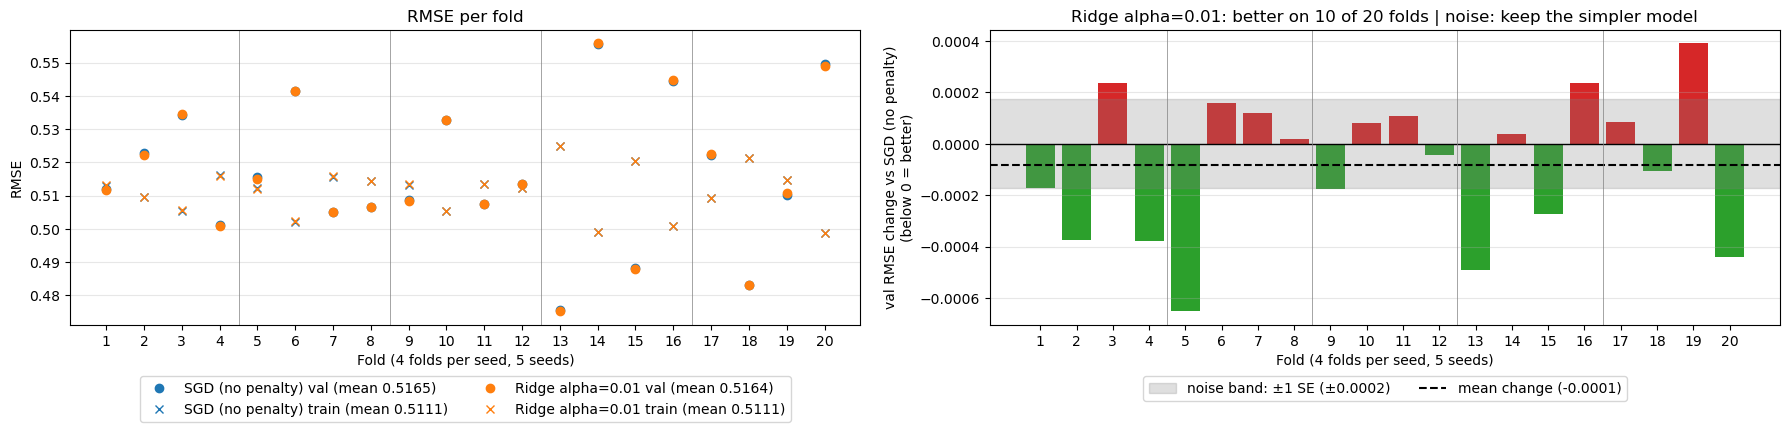

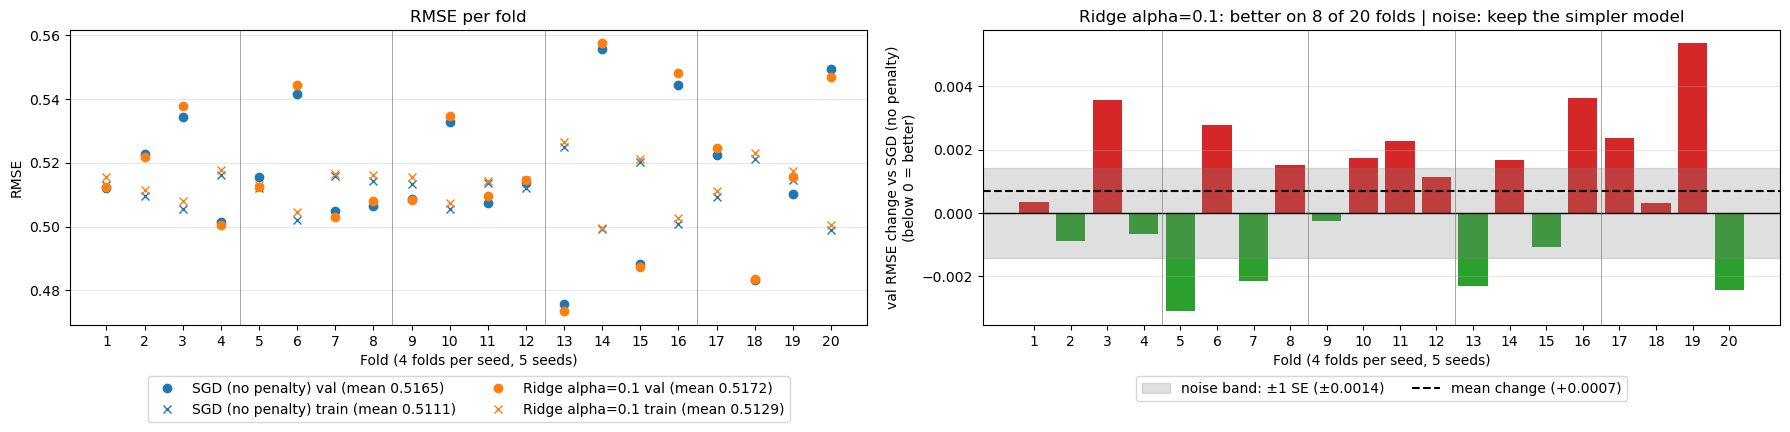

In [22]:
for alpha in ALPHAS:
	ridge_scores[("alpha", alpha)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l2', alpha=alpha, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=ridge_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Ridge alpha={alpha}",
	)

### Ridge > Learning Rate

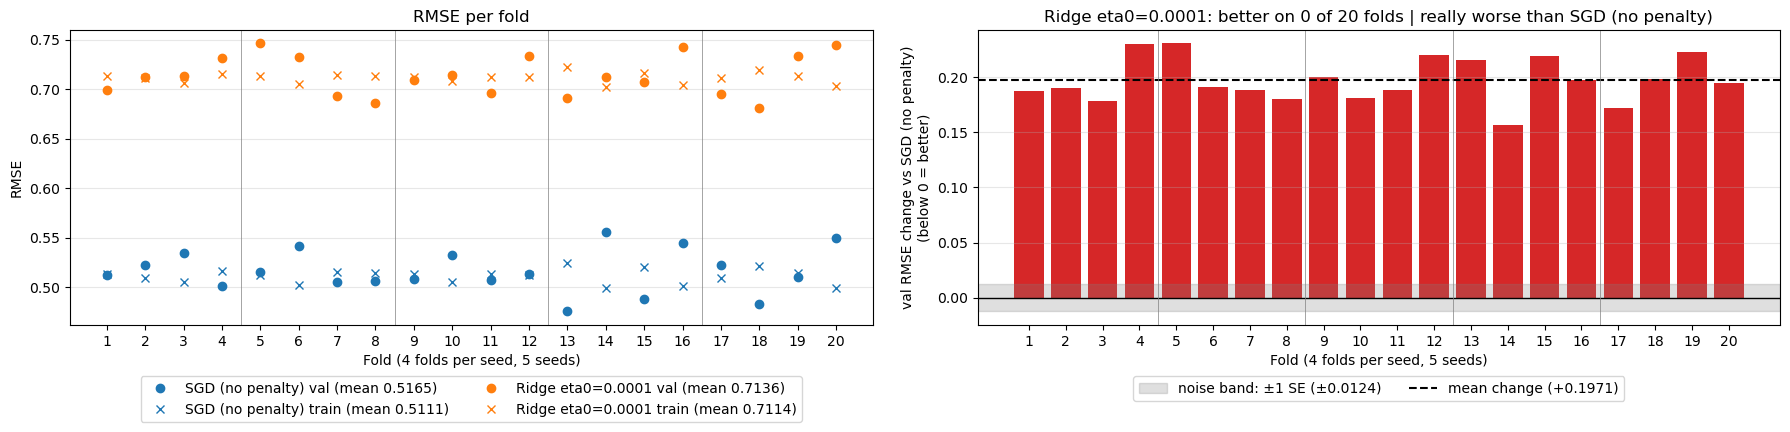

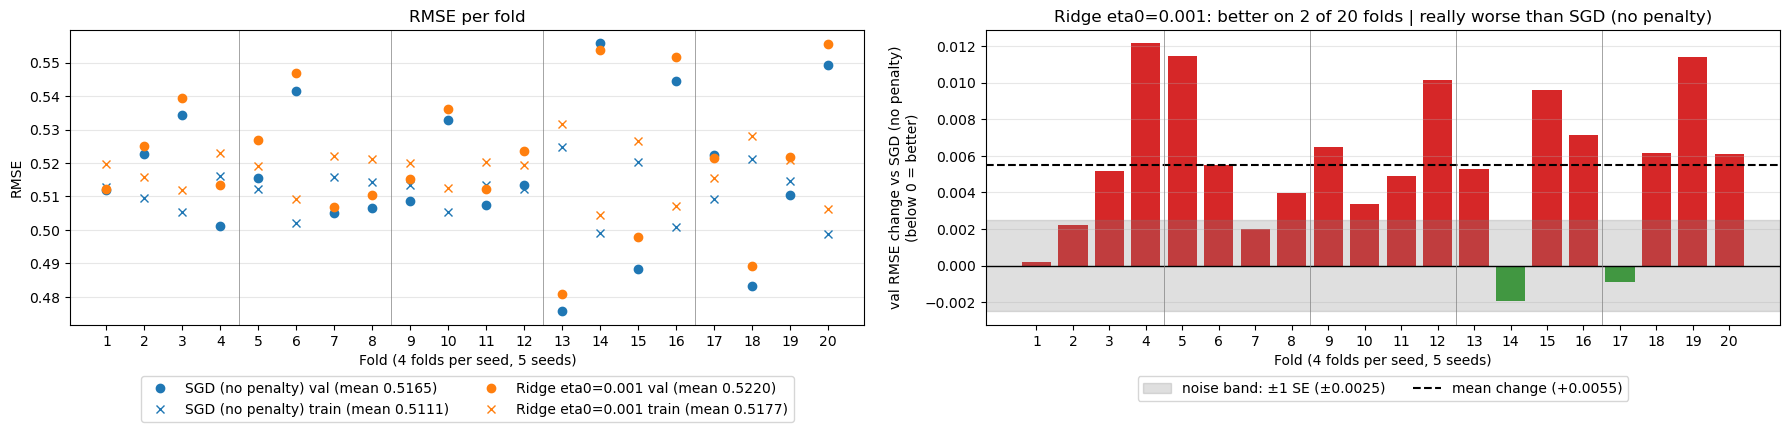

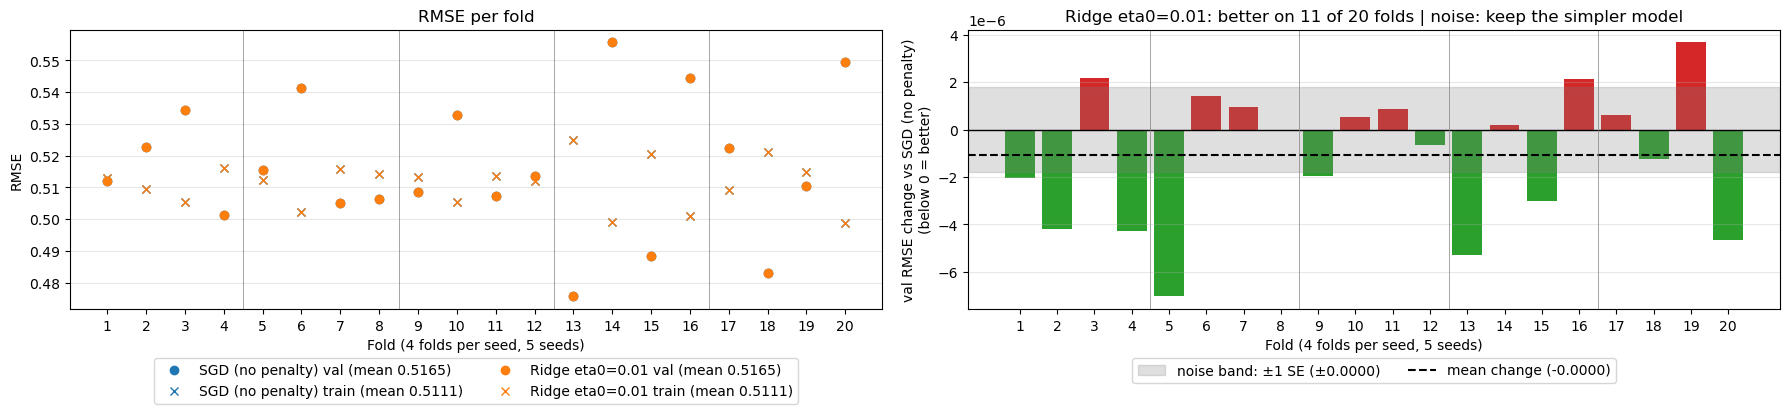

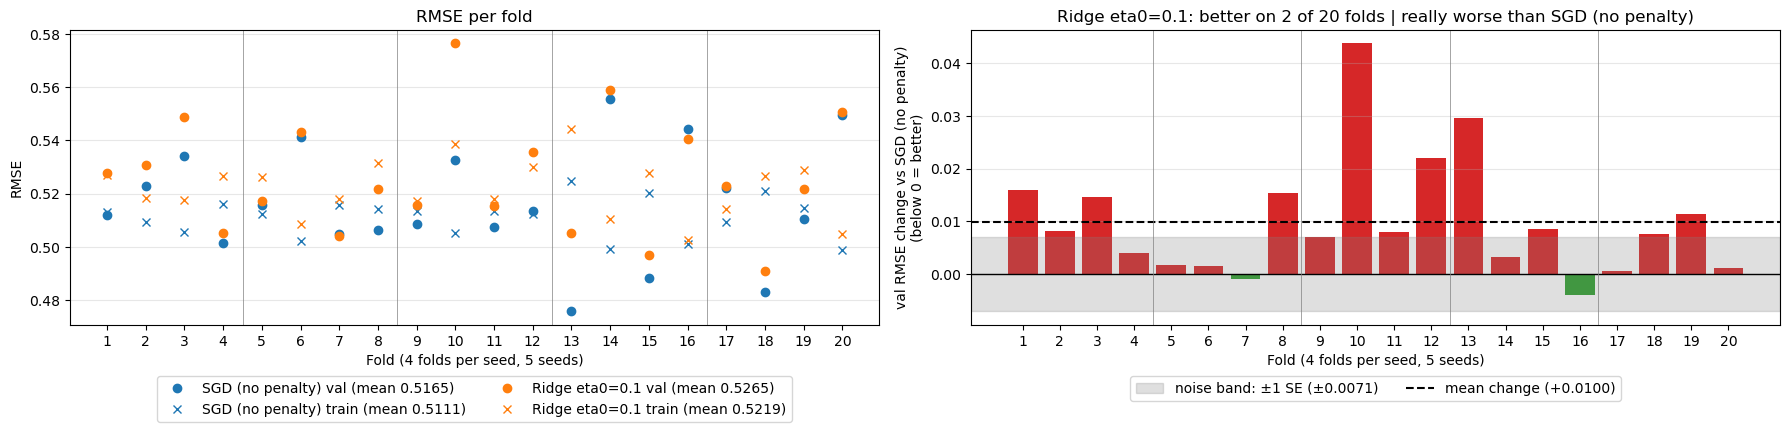

In [23]:
for eta0 in LEARNING_RATES:
	ridge_scores[("eta0", eta0)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='l2', eta0=eta0, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=ridge_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Ridge eta0={eta0}",
	)

## Elastic Net

In [24]:
elasticnet_scores = {}

### Elastic Net > Penalty

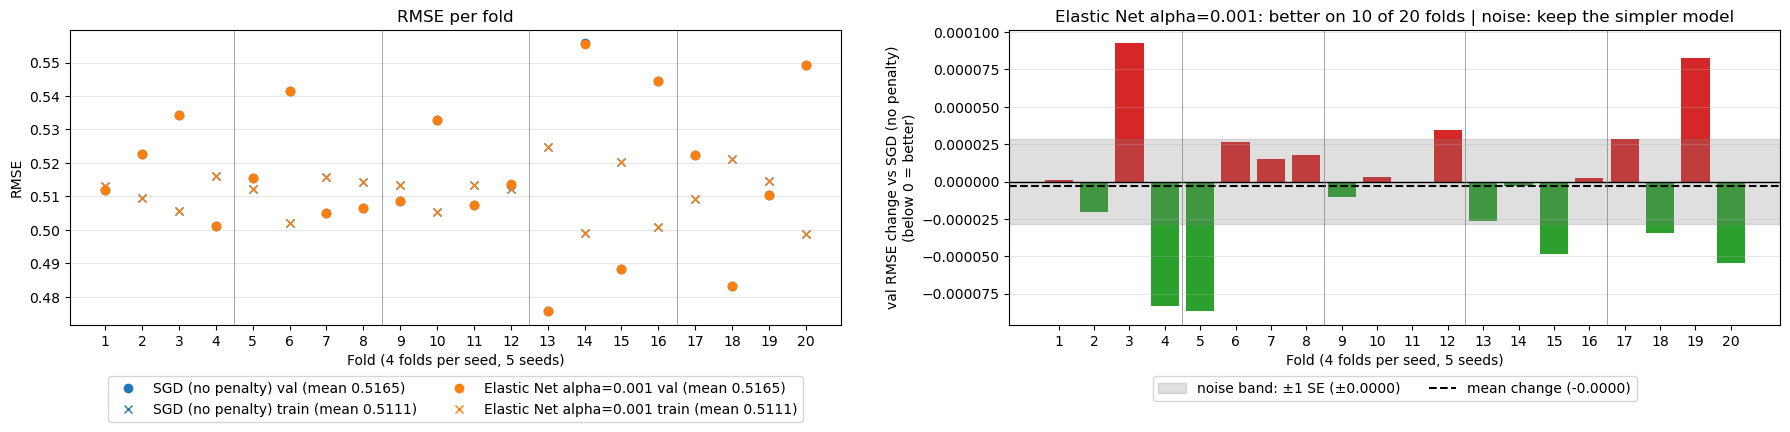

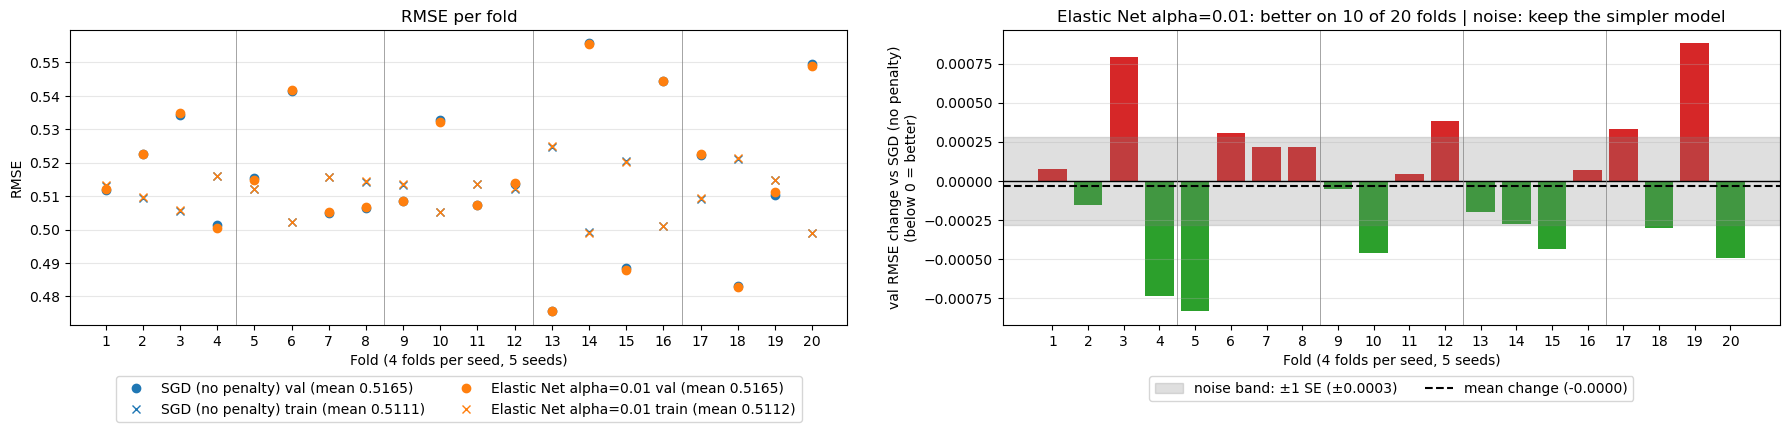

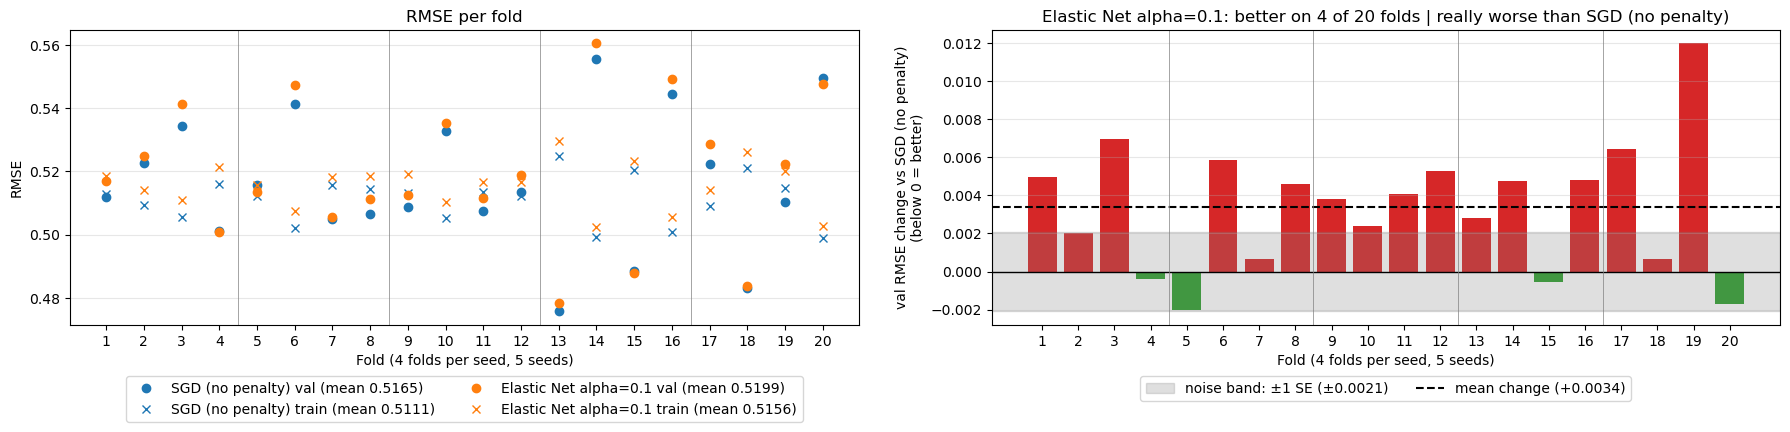

In [25]:
for alpha in ALPHAS:
	elasticnet_scores[("alpha", alpha)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='elasticnet', alpha=alpha, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=elasticnet_scores[("alpha", alpha)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Elastic Net alpha={alpha}",
	)

### Elastic Net > Learning Rate

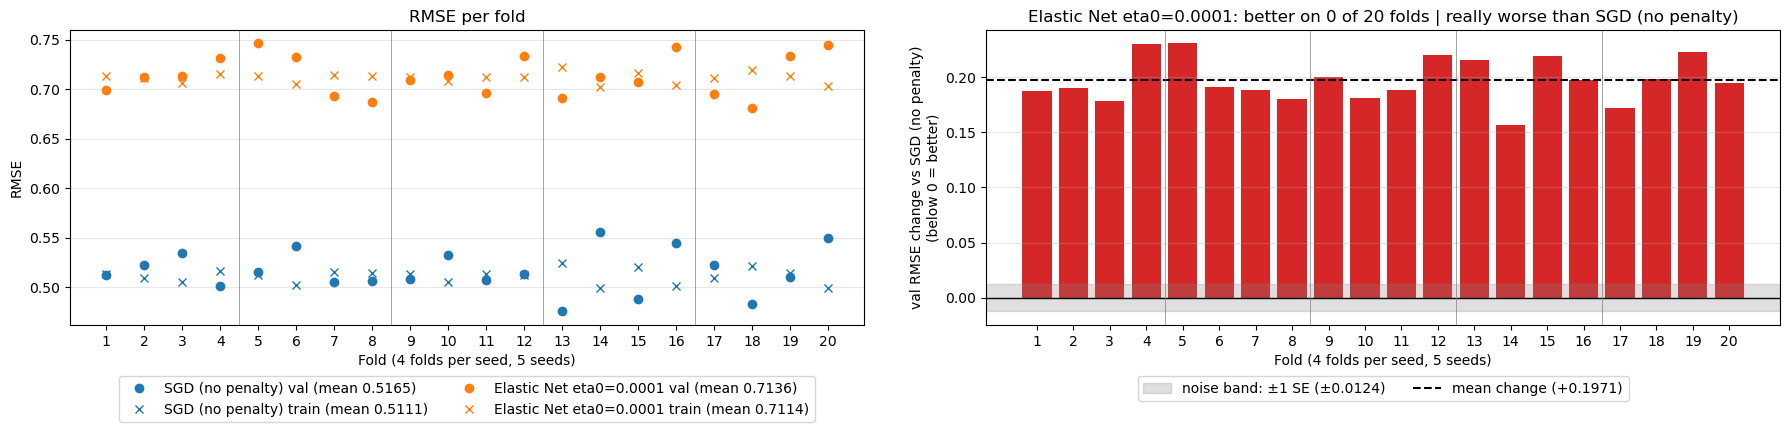

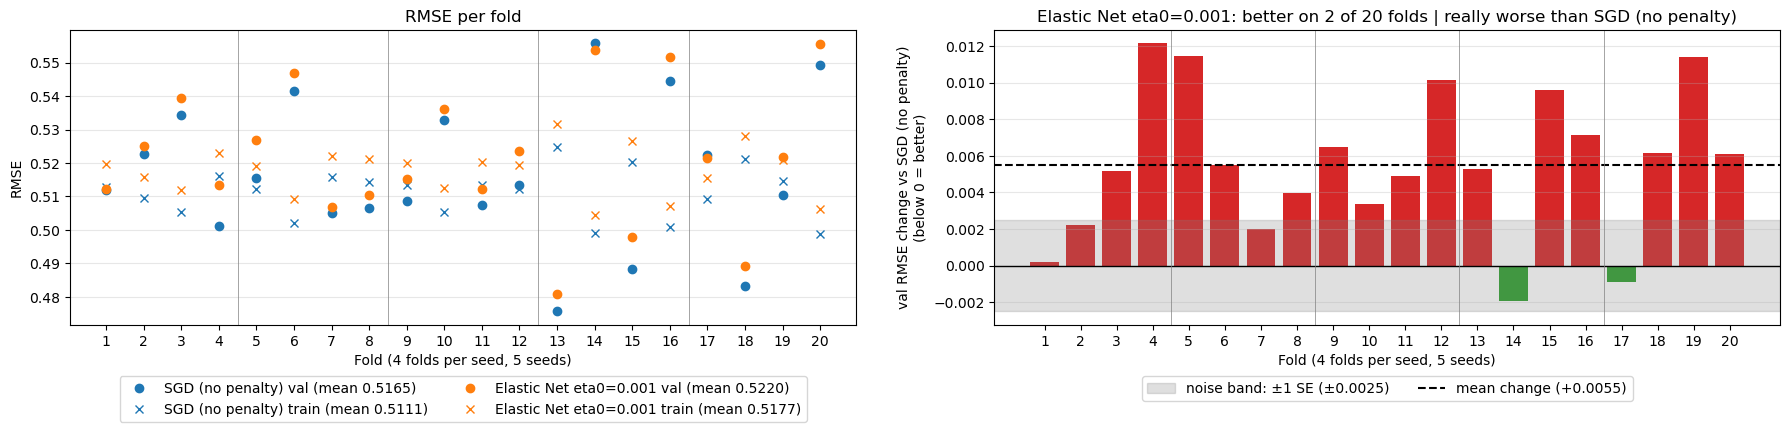

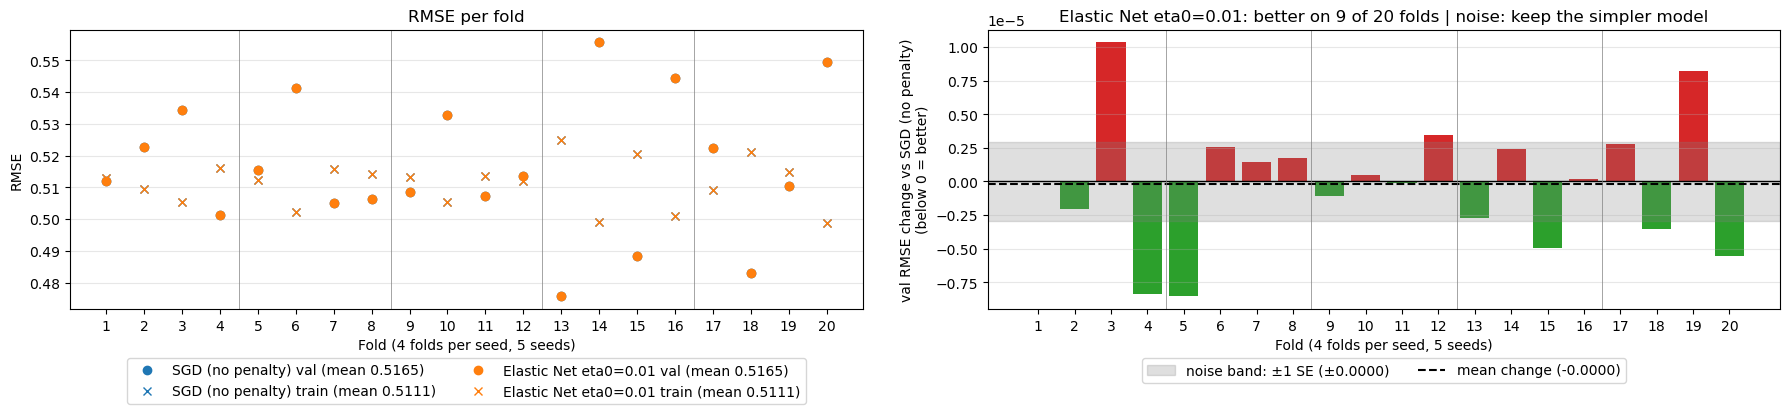

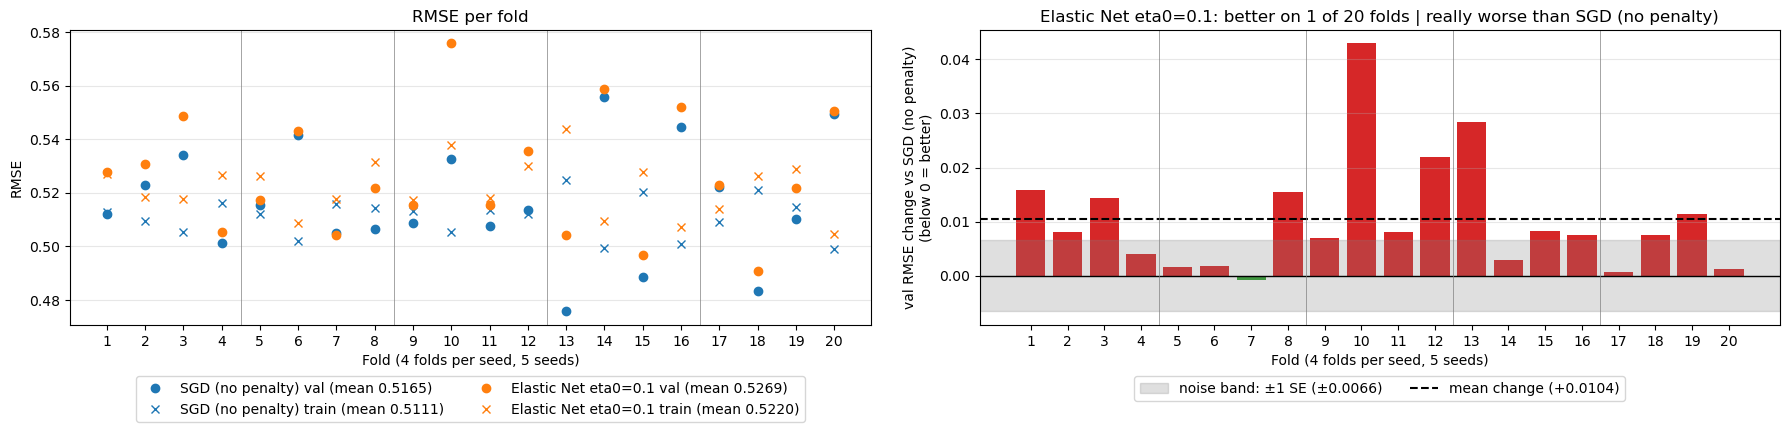

In [26]:
for eta0 in LEARNING_RATES:
	elasticnet_scores[("eta0", eta0)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='elasticnet', eta0=eta0, random_state=42)),
		folds=FOLDS
	)

	cv_fold_scores(
		baseline=(sgd_val_scores, sgd_train_scores),
		compare=elasticnet_scores[("eta0", eta0)],
		baseline_name="SGD (no penalty)",
		compare_name=f"Elastic Net eta0={eta0}",
	)

## Penalty Summary

In [27]:
runs = {"SGD (no penalty)": (sgd_val_scores, sgd_train_scores)}
for name, scores in [("Ridge", ridge_scores), ("Lasso", lasso_scores), ("Elastic Net", elasticnet_scores)]:
	for (hyperparameter, value), val_train in scores.items():
		if hyperparameter == "alpha":
			runs[f"{name} alpha={value}"] = val_train

summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for name, (val, train) in runs.items()
}).T.sort_values("change vs SGD")
summary["folds better"] = summary["folds better"].astype(int)
summary["change vs SGD"] = summary["change vs SGD"].map(np.format_float_positional)
summary

,val RMSE,train RMSE,change vs SGD,SE,folds better
Ridge alpha=0.01,0.516433,0.511120,-0.00008155251713299339,0.000173,10
Elastic Net alpha=0.01,0.516482,0.511167,-0.00003192367899434445,0.000282,10
Ridge alpha=0.001,0.516504,0.511090,-0.000010622446338440228,0.000018,10
Elastic Net alpha=0.001,0.516511,0.511093,-0.0000033012570188173383,0.000029,10
SGD (no penalty),0.516514,0.511089,0.,0.000000,0
Lasso alpha=0.001,0.516545,0.511115,0.00003079145398672545,0.000114,9
Ridge alpha=0.1,0.517207,0.512854,0.0006924889643644599,0.001429,8
Lasso alpha=0.01,0.517475,0.512150,0.0009611813896344412,0.001068,8
Elastic Net alpha=0.1,0.519886,0.515592,0.0033717995755122325,0.002093,4
Lasso alpha=0.1,0.540850,0.536722,0.024335445812585982,0.005229,0


**Impact of the penalty.** At alpha 0.001 and 0.01, Ridge, Lasso and Elastic Net all score within noise of plain SGD (0.5165): every change is smaller than its SE. The lowest is Ridge at alpha 0.01 (0.5164, -0.0001, SE 0.0002), and it is better on only 10 of 20 folds. At alpha 0.1 the penalty starts to hurt. Lasso rises to 0.5408 (+0.0243, SE 0.0052) and is better on 0 of 20 folds, and Elastic Net rises to 0.5199 (+0.0034, SE 0.0021). Both are outside the noise band. Ridge rises least (0.5172, +0.0007, SE 0.0014) and stays within noise. So at the same alpha the L1 penalty costs the most, the L2 penalty the least, and Elastic Net sits between them. Training RMSE rises with validation RMSE (0.5367 for Lasso at alpha 0.1, against 0.5111 for plain SGD), so a strong penalty underfits. A penalty only helps a model that overfits. Here plain SGD's training RMSE (0.5111) is close to its validation RMSE (0.5165), so there is little overfitting to fix.

## Learning Rate Summary

In [28]:
learning_rate_runs = {"SGD (no penalty)": (sgd_val_scores, sgd_train_scores)}
for name, scores in [("Ridge", ridge_scores), ("Lasso", lasso_scores), ("Elastic Net", elasticnet_scores)]:
	for (hyperparameter, value), val_train in scores.items():
		if hyperparameter == "eta0":
			learning_rate_runs[f"{name} eta0={value}"] = val_train

learning_rate_summary = pd.DataFrame({
	name: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for name, (val, train) in learning_rate_runs.items()
}).T.sort_values("change vs SGD")
learning_rate_summary["folds better"] = learning_rate_summary["folds better"].astype(int)
learning_rate_summary["change vs SGD"] = learning_rate_summary["change vs SGD"].map(np.format_float_positional)
learning_rate_summary

,val RMSE,train RMSE,change vs SGD,SE,folds better
Ridge eta0=0.01,0.516513,0.511089,-0.0000010878532057556622,0.000002,11
Elastic Net eta0=0.01,0.516514,0.511089,-0.00000016664227421026024,0.000003,9
SGD (no penalty),0.516514,0.511089,0.,0.000000,0
Lasso eta0=0.01,0.516519,0.511091,0.000004741690287779488,0.000012,8
Ridge eta0=0.001,0.522029,0.517720,0.005514948792044691,0.002508,2
Elastic Net eta0=0.001,0.522030,0.517721,0.005515627239903365,0.002508,2
Lasso eta0=0.001,0.522034,0.517724,0.005519531731252386,0.002506,2
Lasso eta0=0.1,0.526275,0.521111,0.009760770649382161,0.005692,1
Ridge eta0=0.1,0.526474,0.521865,0.009959300290327164,0.007073,2
Elastic Net eta0=0.1,0.526931,0.521963,0.010416993456597504,0.006639,1


**Impact of the learning rate.** Each run changes only eta0 and leaves alpha at its default. eta0 0.01 is the value plain SGD already uses, so at 0.01 all three penalties match it (0.5165). Every other value is worse by more than its SE. At 0.001 all three rise to 0.5220 (+0.0055, SE 0.0025). At 0.1 Lasso rises to 0.5263 (+0.0098, SE 0.0057), Ridge to 0.5265 (+0.0100, SE 0.0071) and Elastic Net to 0.5269 (+0.0104, SE 0.0066). At 0.0001 all three reach 0.7136 (+0.1971, SE 0.0124) and are better on 0 of 20 folds. Training RMSE rises with validation RMSE in every case (0.7114 at 0.0001, against 0.5111 for plain SGD), so a poor learning rate leaves the model underfit, not overfit. The three penalties score almost the same at every eta0, so here the learning rate matters far more than the penalty.

## Hyperparameter Grid
Every combination of penalty, alpha and learning rate (eta0), each compared against plain SGD.

In [29]:
grid_scores = {}
for penalty, alpha, eta0 in product(['l2', 'l1', 'elasticnet'], ALPHAS, LEARNING_RATES):
	grid_scores[(penalty, alpha, eta0)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty=penalty, alpha=alpha, eta0=eta0, random_state=42)),
		folds=FOLDS
	)

grid = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in grid_scores.items()
}).T
grid.index.names = ["penalty", "alpha", "eta0"]
grid["folds better"] = grid["folds better"].astype(int)
grid.sort_values("val RMSE").round(4)

val RMSE  train RMSE  change vs SGD      SE  \
penalty    alpha eta0                                                  
l2         0.010 0.0100    0.5164      0.5111        -0.0001  0.0002   
elasticnet 0.010 0.0100    0.5165      0.5112        -0.0000  0.0003   
l2         0.001 0.0100    0.5165      0.5111        -0.0000  0.0000   
elasticnet 0.001 0.0100    0.5165      0.5111        -0.0000  0.0000   
l1         0.001 0.0100    0.5165      0.5111         0.0000  0.0001   
l2         0.100 0.0100    0.5172      0.5129         0.0007  0.0014   
l1         0.010 0.0100    0.5175      0.5121         0.0010  0.0011   
elasticnet 0.100 0.0100    0.5199      0.5156         0.0034  0.0021   
           0.010 0.0010    0.5220      0.5177         0.0055  0.0024   
l2         0.001 0.0010    0.5220      0.5177         0.0055  0.0025   
elasticnet 0.001 0.0010    0.5220      0.5177         0.0055  0.0025   
l2         0.010 0.0010    0.5221      0.5178         0.0056  0.0025   
l1         0.001 0.0010    0.5221      0.5178         0.0056  0.0025   
           0.010 0.0010    0.5228      0.5186         0.0063  0.0023   
l2         0.100 0.0010    0.5233      0.5194         0.0067  0.0024   
l1         0.010 0.1000    0.5244      0.5201         0.0079  0.0055   
l2         0.100 0.1000    0.5246      0.5208         0.0081  0.0078   
elasticnet 0.010 0.1000    0.5250      0.5205         0.0085  0.0056   
l1         0.001 0.1000    0.5252      0.5206         0.0087  0.0055   
elasticnet 0.001 0.1000    0.5256      0.5202         0.0091  0.0052   
           0.100 0.0010    0.5258      0.5221         0.0092  0.0027   
l2         0.010 0.1000    0.5262      0.5218         0.0097  0.0072   
           0.001 0.1000    0.5264      0.5219         0.0099  0.0071   
elasticnet 0.100 0.1000    0.5265      0.5228         0.0100  0.0069   
l1         0.100 0.0100    0.5408      0.5367         0.0243  0.0052   
                 0.0010    0.5453      0.5423         0.0287  0.0050   
                 0.1000    0.5463      0.5425         0.0298  0.0111   
l2         0.010 0.0001    0.7136      0.7114         0.1971  0.0125   
elasticnet 0.010 0.0001    0.7136      0.7114         0.1971  0.0124   
l2         0.001 0.0001    0.7136      0.7114         0.1971  0.0124   
elasticnet 0.001 0.0001    0.7137      0.7115         0.1971  0.0124   
l1         0.001 0.0001    0.7137      0.7115         0.1972  0.0124   
           0.010 0.0001    0.7144      0.7122         0.1979  0.0123   
l2         0.100 0.0001    0.7147      0.7127         0.1982  0.0124   
elasticnet 0.100 0.0001    0.7168      0.7148         0.2003  0.0124   
l1         0.100 0.0001    0.7298      0.7282         0.2133  0.0143   

                         folds better  
penalty    alpha eta0                  
l2         0.010 0.0100            10  
elasticnet 0.010 0.0100            10  
l2         0.001 0.0100            10  
elasticnet 0.001 0.0100            10  
l1         0.001 0.0100             9  
l2         0.100 0.0100             8  
l1         0.010 0.0100             8  
elasticnet 0.100 0.0100             4  
           0.010 0.0010             3  
l2         0.001 0.0010             2  
elasticnet 0.001 0.0010             2  
l2         0.010 0.0010             2  
l1         0.001 0.0010             2  
           0.010 0.0010             0  
l2         0.100 0.0010             0  
l1         0.010 0.1000             0  
l2         0.100 0.1000             3  
elasticnet 0.010 0.1000             2  
l1         0.001 0.1000             2  
elasticnet 0.001 0.1000             1  
           0.100 0.0010             0  
l2         0.010 0.1000             2  
           0.001 0.1000             2  
elasticnet 0.100 0.1000             0  
l1         0.100 0.0100             0  
                 0.0010             0  
                 0.1000             0  
l2         0.010 0.0001             0  
elasticnet 0.010 0.0001             0  
l2         0.001 0.0001             0  
elasticn

### Elastic Net l1_ratio
Elastic Net only: l1_ratio sets the mix of the two penalties (0 = all Ridge, 1 = all Lasso). Ridge and Lasso ignore it.

In [30]:
L1_RATIOS = [0.15, 0.5, 0.85]

elasticnet_grid_scores = {}
for alpha, eta0, l1_ratio in product(ALPHAS, LEARNING_RATES, L1_RATIOS):
	elasticnet_grid_scores[(alpha, eta0, l1_ratio)] = CROSS_VALIDATION.cv_model(
		data=train_df,
		columns=BEST_FEATURES,
		estimator=make_pipeline(StandardScaler(), SGDRegressor(penalty='elasticnet', alpha=alpha, eta0=eta0, l1_ratio=l1_ratio, random_state=42)),
		folds=FOLDS
	)

elasticnet_grid = pd.DataFrame({
	key: {
		"val RMSE": val.mean(),
		"train RMSE": train.mean(),
		"change vs SGD": (val - sgd_val_scores).mean(),
		"SE": standard_error(diff=val - sgd_val_scores),
		"folds better": np.sum(val < sgd_val_scores),
	}
	for key, (val, train) in elasticnet_grid_scores.items()
}).T
elasticnet_grid.index.names = ["alpha", "eta0", "l1_ratio"]
elasticnet_grid["folds better"] = elasticnet_grid["folds better"].astype(int)
elasticnet_grid.sort_values("val RMSE").round(4)

val RMSE  train RMSE  change vs SGD      SE  \
alpha eta0   l1_ratio                                                
0.010 0.0100 0.15        0.5165      0.5112        -0.0000  0.0003   
0.001 0.0100 0.15        0.5165      0.5111        -0.0000  0.0000   
             0.50        0.5165      0.5111         0.0000  0.0001   
             0.85        0.5165      0.5111         0.0000  0.0001   
0.010 0.0100 0.50        0.5168      0.5115         0.0003  0.0006   
             0.85        0.5173      0.5119         0.0008  0.0009   
0.100 0.0100 0.15        0.5199      0.5156         0.0034  0.0021   
0.010 0.0010 0.15        0.5220      0.5177         0.0055  0.0024   
0.001 0.0010 0.15        0.5220      0.5177         0.0055  0.0025   
             0.50        0.5221      0.5177         0.0055  0.0025   
             0.85        0.5221      0.5178         0.0056  0.0025   
0.010 0.0010 0.50        0.5222      0.5179         0.0057  0.0023   
             0.85        0.5225      0.5183         0.0060  0.0023   
      0.1000 0.50        0.5242      0.5197         0.0077  0.0056   
0.001 0.1000 0.50        0.5244      0.5198         0.0079  0.0053   
0.010 0.1000 0.85        0.5248      0.5202         0.0083  0.0055   
             0.15        0.5250      0.5205         0.0085  0.0056   
0.001 0.1000 0.85        0.5252      0.5206         0.0087  0.0055   
             0.15        0.5256      0.5202         0.0091  0.0052   
0.100 0.0010 0.15        0.5258      0.5221         0.0092  0.0027   
      0.1000 0.15        0.5265      0.5228         0.0100  0.0069   
      0.0100 0.50        0.5287      0.5243         0.0122  0.0035   
      0.0010 0.50        0.5342      0.5306         0.0177  0.0037   
      0.0100 0.85        0.5367      0.5325         0.0202  0.0047   
      0.1000 0.50        0.5380      0.5329         0.0214  0.0096   
             0.85        0.5409      0.5360         0.0244  0.0088   
      0.0010 0.85        0.5415      0.5384         0.0250  0.0046   
0.010 0.0001 0.15        0.7136      0.7114         0.1971  0.0124   
0.001 0.0001 0.15        0.7137      0.7115         0.1971  0.0124   
             0.50        0.7137      0.7115         0.1972  0.0124   
             0.85        0.7137      0.7115         0.1972  0.0124   
0.010 0.0001 0.50        0.7138      0.7116         0.1973  0.0124   
             0.85        0.7141      0.7120         0.1976  0.0123   
0.100 0.0001 0.15        0.7168      0.7148         0.2003  0.0124   
             0.50        0.7224      0.7204         0.2059  0.0132   
             0.85        0.7270      0.7253         0.2105  0.0138   

                       folds better  
alpha eta0   l1_ratio                
0.010 0.0100 0.15                10  
0.001 0.0100 0.15                10  
             0.50                 9  
             0.85                 9  
0.010 0.0100 0.50                 8  
             0.85                 8  
0.100 0.0100 0.15                 4  
0.010 0.0010 0.15                 3  
0.001 0.0010 0.15                 2  
             0.50                 2  
             0.85                 2  
0.010 0.0010 0.50                 1  
             0.85                 0  
      0.1000 0.50                 2  
0.001 0.1000 0.50                 2  
0.010 0.1000 0.85                 0  
             0.15                 2  
0.001 0.1000 0.85                 2  
             0.15                 1  
0.100 0.0010 0.15                 0  
      0.1000 0.15                 0  
      0.0100 0.50                 0  
      0.0010 0.50                 0  
      0.0100 0.85                 0  
      0.1000 0.50                 0  
             0.85                 0  
      0.0010 0.85                 0  
0.010 0.0001 0.15                 0  
0.001 0.0001 0.15                 0  
             0.50                 0  
             0.85                 0  
0.010 0.0001 0.50                 0  
             0.85                 0  
0.100 0.0001 0.15               

**Impact of combining the hyperparameters, and of l1_ratio.** The Hyperparameter Grid sorts mainly by eta0. Eight of the nine eta0 0.01 rows lead the table (0.5164 to 0.5199). The rows with eta0 0.001 or 0.1 follow (0.5220 to 0.5265), and every eta0 0.0001 row is at the bottom (0.7136 to 0.7298). The exception is Lasso at alpha 0.1, which scores 0.5408 or worse at every eta0. The best row, Ridge with alpha 0.01 and eta0 0.01 (0.5164), is the same setting the single experiments found, so no combination of alpha and eta0 beats choosing them one at a time.

l1_ratio only matters when alpha is large. At eta0 0.01 it changes nothing at alpha 0.001 (0.5165 at all three values) and little at alpha 0.01 (0.5165, 0.5168 and 0.5173, each change smaller than its SE). At alpha 0.1 more L1 is clearly worse: 0.5199 at l1_ratio 0.15, 0.5287 at 0.5 (+0.0122, SE 0.0035) and 0.5367 at 0.85 (+0.0202, SE 0.0047). This matches the penalty findings: a strong L1 penalty costs the most.

# Selected Model
Ridge (`penalty='l2'`) with alpha 0.01 and eta0 0.01 has the lowest validation RMSE of the regularized runs. It is the top row of the Penalty Summary and of the Hyperparameter Grid (0.5164). It is within noise of plain SGD (-0.0001, SE 0.0002), so the penalty does not improve the model, but it is the best-performing regularized setting. eta0 stays at 0.01 because every other learning rate is worse by more than its SE.

In [31]:
BEST_PENALTY = 'l2'
BEST_ALPHA = 0.01
BEST_ETA0 = 0.01

best_val_scores, best_train_scores = grid_scores[(BEST_PENALTY, BEST_ALPHA, BEST_ETA0)]
print(f"val RMSE {best_val_scores.mean():.4f} | train RMSE {best_train_scores.mean():.4f}")

val RMSE 0.5164 | train RMSE 0.5111


## Train on the Entire Training Set
The selected model is fit once on every complete training row. No rows are held out here, so only a training RMSE can be reported.

The hinge columns of `BEST_FEATURES` were added to `train_df` by hand in the Feature Shapes section. Here they are built inside the pipeline by `add_hinge_columns` (`Q1/utils/features/hinge_columns.py`), so the fitted pipeline takes the 8 raw columns and makes the same 11 columns itself. That way the saved model can predict on new data with no preprocessing outside it.

In [32]:
final_train_df = train_df.dropna()
print(f"rows: {len(final_train_df)}")

final_model = make_pipeline(
	# builds the hinge columns from the raw columns: 8 raw columns in, the 11 BEST_FEATURES columns out
	FunctionTransformer(add_hinge_columns),
	StandardScaler(),
	SGDRegressor(penalty=BEST_PENALTY, alpha=BEST_ALPHA, eta0=BEST_ETA0, random_state=42),
)
final_model.fit(final_train_df[FEATURES], final_train_df[TARGET])

final_train_rmse = CROSS_VALIDATION.rmse_of(final_train_df[TARGET], final_model.predict(final_train_df[FEATURES]))
print(f"train RMSE {final_train_rmse:.4f} | epochs run {final_model[-1].n_iter_}")

rows: 1374
train RMSE 0.5115 | epochs run 8


**Final model.** The selected model, Ridge with alpha 0.01 and eta0 0.01 on the 11 `BEST_FEATURES` columns, is fit on all 1374 complete training rows and stops after 8 epochs. Its training RMSE is 0.5115. That is close to the same model's training RMSE (0.5111) and validation RMSE (0.5164) across the 20 folds, so the model fit on every row behaves like the models fit on the folds. The validation RMSE of 0.5164 is the estimate of how it scores on rows it has not seen.

## Save the Model
The fitted pipeline is saved to `Q1/MODELS`, so Part F can load it and predict on the test data.

In [33]:
MODEL_OUTPUT_DIR.mkdir(exist_ok=True)

model_path = MODEL_OUTPUT_DIR / 'linear_regression.joblib'
joblib.dump(final_model, model_path)
print(f"saved: {model_path.name}")

saved: linear_regression.joblib


## Training and Validation Loss by Epoch
SGD normally runs all its epochs inside one `fit` call. To see each epoch, the model is built with `max_iter=1` and `warm_start=True`: every `fit` call runs one more epoch, starting from the coefficients the previous call ended with. `tol=None` turns off early stopping, so every call runs its one epoch.

A validation loss needs rows the model does not train on, so this uses the first of the 20 folds: the model trains on that fold's training rows and is scored on its validation rows after every epoch.

In [34]:
EPOCHS = 30

train_index, val_index = FOLDS[0]
epoch_train_df = train_df.loc[train_index].dropna()
epoch_val_df = train_df.loc[val_index]
print(f"train rows: {len(epoch_train_df)} | validation rows: {len(epoch_val_df)}")

epoch_model = make_pipeline(
	StandardScaler(),
	SGDRegressor(penalty=BEST_PENALTY, alpha=BEST_ALPHA, eta0=BEST_ETA0, max_iter=1, tol=None, warm_start=True, random_state=42),
)

epoch_train_rmse, epoch_val_rmse = [], []
for epoch in range(EPOCHS):
	# one more epoch, continuing from the coefficients of the previous call
	epoch_model.fit(epoch_train_df[BEST_FEATURES], epoch_train_df[TARGET])
	epoch_train_rmse.append(CROSS_VALIDATION.rmse_of(epoch_train_df[TARGET], epoch_model.predict(epoch_train_df[BEST_FEATURES])))
	epoch_val_rmse.append(CROSS_VALIDATION.rmse_of(epoch_val_df[TARGET], epoch_model.predict(epoch_val_df[BEST_FEATURES])))

epoch_scores = pd.DataFrame(
	{"train RMSE": epoch_train_rmse, "val RMSE": epoch_val_rmse},
	index=pd.RangeIndex(1, EPOCHS + 1, name="epoch"),
)
epoch_scores.loc[[1, 2, 3, 4, 5, 10, 15, 20, 30]].round(4)

train rows: 1030 | validation rows: 344


,train RMSE,val RMSE
epoch,,
1,0.7090,0.6992
2,0.5174,0.5086
3,0.5139,0.5087
4,0.5134,0.5098
5,0.5132,0.5104
10,0.5131,0.5112
15,0.5131,0.5113
20,0.5131,0.5114
30,0.5131,0.5114


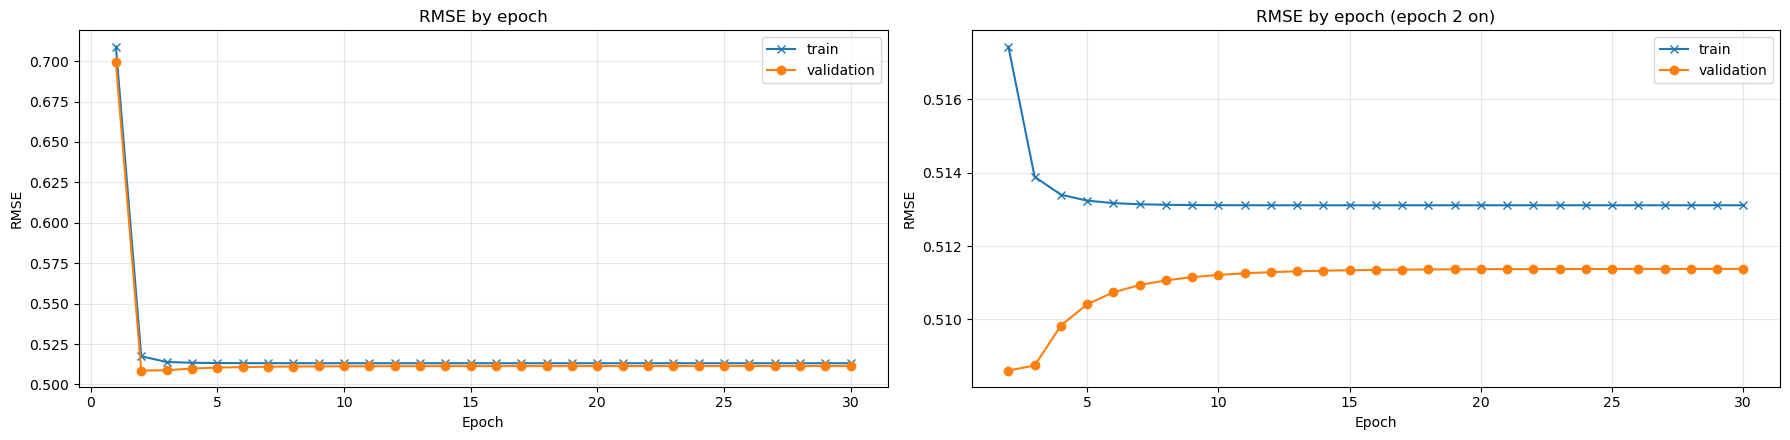

In [35]:
fig, (ax_all, ax_zoom) = plt.subplots(1, 2, figsize=(18, 4.5))

# left: every epoch. right: from epoch 2 on, where the two lines can be told apart
for ax, scores, title in [
	(ax_all, epoch_scores, "RMSE by epoch"),
	(ax_zoom, epoch_scores.loc[2:], "RMSE by epoch (epoch 2 on)"),
]:
	ax.plot(scores.index, scores["train RMSE"], "x-", color="C0", label="train")
	ax.plot(scores.index, scores["val RMSE"], "o-", color="C1", label="validation")
	ax.set_xlabel("Epoch")
	ax.set_ylabel("RMSE")
	ax.set_title(title)
	ax.grid(alpha=0.3)
	ax.legend()

plt.tight_layout()
plt.show()

**Training and validation loss by epoch.** The curve uses the first fold: 1030 training rows and 344 validation rows. Almost all the learning happens in one epoch. From epoch 1 to epoch 2, training RMSE falls from 0.7090 to 0.5174 and validation RMSE from 0.6992 to 0.5086. After that the changes are small. Training RMSE keeps falling and is flat at 0.5131 from epoch 10 on. Validation RMSE is lowest at epoch 2 (0.5086), rises slowly to 0.5112 by epoch 10 and is flat at 0.5114 from epoch 20 on. Validation RMSE rising while training RMSE falls is the pattern of overfitting, but here it is small and it stops: both lines are flat from epoch 20 on, and validation RMSE ends below training RMSE (0.5114 against 0.5131). The model converges within about 10 epochs, and more epochs neither help nor hurt.

# Reproducibility
Every random step is seeded. The 20 folds come from `KFold` with the seeds in `SEEDS`, and every `SGDRegressor` and the iterative imputer use `random_state=42`. Running the notebook again from the top gives the same numbers.